
# Credit Card Fraud Detection Using Machine Learning

## Notebook 01: Data Understanding and Data Cleaning

### **Project Overview**
The objective of this project is to develop a Machine Learning-based system to identify fraudulent credit card transactions.

### **Objectives**
1. Understand the dataset structure.
2. Identify columns and their data types.
3. Detect missing values.
4. Identify duplicate records.
5. Examine the target variables.
6. Understand transaction patterns and time periods.
7. Identify potential data quality issues and data leakage.

### **Tools and Technologies**
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Imbalanced-learn

### **Dataset**
Credit Card Fraud Detection and Drift Dataset (2026).


## 1. Data Understanding and Initial Exploration

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the dataset
df = pd.read_csv(
    '../data/raw/credit_card_fraud_drift_2026.csv'
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display number of rows and columns
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 120000
Number of Columns: 73


In [4]:
df.head()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_country,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,failed_auth_attempts_24h,device_change_7d,billing_shipping_mismatch,account_profile_change_7d,merchant_velocity_24h,prior_dispute_ratio_90d,pos_entry_fallback,pin_retry_count_24h,concept_drift_score,population_shift_index,covariate_shift_flag,synthetic_id_camouflage_score,label_available,label_delay_days,pseudo_label,is_fraud,fraud_type,fraud_amount_lost,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
0,TX4042000000000,CU00022008,CA000000001,ME000381,2026-01-01 00:00:00,1,1,1,0,0.0,16.34,subscription,SG,0,Thursday,0,36,M,GB,139,21245.40,647,5,0,0,0,0.0,0.0,90.0,55.96,4.55,0,0,0.3268,0,0,mobile_app,unknown_device,Chrome,0,50.0,20.0,0,0,outlook.com,1,0,0,0,0,0.0,1,0,0.0117,0.0614,0,0.0,1,0,-1,0,Legitimate,0.0,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
1,TX4042000000001,CU00000598,CA000000002,ME000764,2026-01-01 00:00:00,1,1,1,0,0.0,27.88,grocery,IE,0,Thursday,0,40,F,IE,937,3382.44,639,1,0,0,0,0.0,0.0,90.0,31.44,18.14,1,0,0.5576,0,0,mobile_app,mobile,in_app,0,50.0,20.0,0,0,icloud.com,0,0,0,0,0,0.0,0,0,0.0262,0.0471,0,0.0,1,0,-1,0,Legitimate,0.0,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
2,TX4042000000002,CU00018179,CA000000003,ME001251,2026-01-01 00:03:00,1,1,1,0,0.0,24.71,grocery,IN,0,Thursday,1,56,F,US,313,2405.17,719,2,0,0,0,0.0,0.0,90.0,2.87,4.29,0,0,0.4942,0,0,POS,physical_terminal,none,0,50.0,20.0,0,0,business.com,2,0,0,0,0,0.0,0,0,0.0333,0.0579,0,0.0,1,0,-1,0,Legitimate,0.0,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
3,TX4042000000003,CU00023636,CA000000004,ME002627,2026-01-01 00:04:00,1,1,1,0,0.0,62.07,electronics,US,0,Thursday,1,27,M,US,266,3215.98,638,1,0,0,0,0.0,0.0,90.0,6.77,14.30,1,0,1.2414,1,1,POS,physical_terminal,none,0,50.0,20.0,0,0,gmail.com,1,0,0,0,0,0.0,0,0,0.0000,0.0000,0,0.0,1,0,-1,0,Legitimate,0.0,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
4,TX4042000000004,CU00028521,CA000000005,ME004940,2026-01-01 00:05:00,1,1,1,0,0.0,46.23,health,US,0,Thursday,1,21,F,US,796,3937.88,786,3,0,0,0,0.0,0.0,90.0,7.50,5.03,0,1,0.9246,1,1,POS,physical_terminal,none,0,50.0,20.0,0,0,yahoo.com,0,0,0,0,0,0.0,0,1,0.0130,0.0291,0,0.0,1,0,-1,0,Legitimate,0.0,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period


In [5]:
df.tail()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_country,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,failed_auth_attempts_24h,device_change_7d,billing_shipping_mismatch,account_profile_change_7d,merchant_velocity_24h,prior_dispute_ratio_90d,pos_entry_fallback,pin_retry_count_24h,concept_drift_score,population_shift_index,covariate_shift_flag,synthetic_id_camouflage_score,label_available,label_delay_days,pseudo_label,is_fraud,fraud_type,fraud_amount_lost,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
119995,TX4042000119995,CU00028819,CA000006557,ME003141,2026-06-30 23:53:00,6,27,4,29,0.48,38.77,fuel,CA,23,Tuesday,1,53,M,US,633,10662.73,759,1,0,0,0,0.0,0.0,35.262,13.45,1.80,0,0,0.7754,1,1,POS,physical_terminal,none,0,50.00,20.00,0,0,icloud.com,1,0,0,0,0,0.0,0,0,0.4798,0.3960,0,0.0,0,7,0,0,Legitimate,0.0,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119996,TX4042000119996,CU00027633,CA000006431,ME000713,2026-06-30 23:54:00,6,27,4,29,0.48,47.61,subscription,CA,23,Tuesday,0,18,M,IN,301,3304.92,714,2,0,0,0,0.0,0.0,69.544,8.25,21.05,0,0,0.9522,0,0,ecommerce,desktop,in_app,0,50.00,20.00,0,0,yahoo.com,0,0,0,0,1,0.0,0,0,0.4967,0.3450,0,0.0,0,7,0,0,Legitimate,0.0,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119997,TX4042000119997,CU00007909,CA000007841,ME002856,2026-06-30 23:55:00,6,27,4,29,0.48,49.38,grocery,US,23,Tuesday,0,43,F,IN,822,3706.06,725,3,0,0,0,0.0,0.0,59.999,66.64,19.86,0,0,0.9876,0,0,ecommerce,tablet,in_app,0,50.00,20.00,0,0,gmail.com,1,0,0,0,0,0.0,0,0,0.5079,0.4644,1,0.0,0,21,0,0,Legitimate,0.0,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119998,TX4042000119998,CU00025126,CA000009491,ME004006,2026-06-30 23:57:00,6,27,4,29,0.48,37.66,health,US,23,Tuesday,1,46,F,IE,274,1608.68,617,3,0,0,1,0.0,0.0,4.224,3.04,43.58,1,0,1.7615,0,0,POS,physical_terminal,none,0,21.38,0.00,0,0,yahoo.com,0,0,0,0,1,0.0,0,0,0.5497,0.4732,1,0.0,0,14,0,0,Legitimate,0.0,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119999,TX4042000119999,CU00014288,CA000029099,ME003500,2026-06-30 23:58:00,6,27,4,29,0.48,49.94,restaurant,IN,23,Tuesday,1,57,F,US,352,5555.88,636,2,0,0,2,0.0,0.0,3.919,0.72,3.12,0,0,1.6560,1,1,ATM,physical_terminal,none,0,30.16,10.22,0,0,other,0,0,0,0,0,0.0,0,0,0.4727,0.4662,1,0.0,0,7,1,0,Legitimate,0.0,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period


In [6]:
print("Dataset Columns:")

for column in df.columns:
    print(column)

Dataset Columns:
transaction_id
customer_id
card_id
merchant_id
transaction_datetime
month
week_of_year
drift_phase
days_into_phase
drift_magnitude
transaction_amount
merchant_category
merchant_country
transaction_hour
transaction_day_of_week
card_present
customer_age
customer_gender
customer_country
account_age_days
credit_limit
credit_score
num_cards_held
transactions_last_1h
transactions_last_24h
transactions_last_7d
amount_last_1h
amount_last_24h
days_since_last_transaction
distance_from_home_km
distance_from_last_tx_km
international_transaction
high_risk_country
amount_vs_avg_ratio
used_chip
used_pin
transaction_channel
device_type
browser
is_weekend
avg_transaction_amount_30d
std_transaction_amount_30d
num_declined_last_30d
num_chargebacks_ever
email_domain
failed_auth_attempts_24h
device_change_7d
billing_shipping_mismatch
account_profile_change_7d
merchant_velocity_24h
prior_dispute_ratio_90d
pos_entry_fallback
pin_retry_count_24h
concept_drift_score
population_shift_index
cova

In [7]:
# Check data types and non-null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 73 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   transaction_id                      120000 non-null  str    
 1   customer_id                         120000 non-null  str    
 2   card_id                             120000 non-null  str    
 3   merchant_id                         120000 non-null  str    
 4   transaction_datetime                120000 non-null  str    
 5   month                               120000 non-null  int64  
 6   week_of_year                        120000 non-null  int64  
 7   drift_phase                         120000 non-null  int64  
 8   days_into_phase                     120000 non-null  int64  
 9   drift_magnitude                     120000 non-null  float64
 10  transaction_amount                  120000 non-null  float64
 11  merchant_category                   1

In [8]:
# Check descriptive statistics
df.describe(include = 'all')

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_country,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,failed_auth_attempts_24h,device_change_7d,billing_shipping_mismatch,account_profile_change_7d,merchant_velocity_24h,prior_dispute_ratio_90d,pos_entry_fallback,pin_retry_count_24h,concept_drift_score,population_shift_index,covariate_shift_flag,synthetic_id_camouflage_score,label_available,label_delay_days,pseudo_label,is_fraud,fraud_type,fraud_amount_lost,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
count,120000,120000,120000,120000,120000,120000.000000,120000.00000,120000.000000,120000.000000,120000.000000,120000.000000,120000,120000,120000.000000,120000,120000.000000,120000.000000,120000,120000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.00000,120000.000000,120000,120000,120000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000,120000.000000,120000,120000.000000,120000.000000,120000,120000.000000,120000.000000,2693.000000,2693,2693,120000
unique,120000,29441,29441,5000,95905,NaN,NaN,NaN,NaN,NaN,NaN,10,12,NaN,7,NaN,NaN,4,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,5,6,NaN,NaN,NaN,NaN,NaN,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,NaN,4,NaN,NaN,6,NaN,NaN,NaN,2680,2675,2
top,TX4042000000000,CU00008340,CA000019501,ME001114,2026-01-21 08:49:00,NaN,NaN,NaN,NaN,NaN,NaN,retail,US,NaN,Tuesday,NaN,NaN,F,US,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POS,physical_terminal,none,NaN,NaN,NaN,NaN,NaN,gmail.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Legitimate,NaN,peak_drift,NaN,NaN,Legitimate,NaN,NaN,NaN,2026-03-03 11:24:00,2026-03-17 18:42:00,later_period
freq,1,15,15,44,6,NaN,NaN,NaN,NaN,NaN,NaN,21324,58166,NaN,17465,NaN,NaN,58506,48663,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50226,56084,60501,NaN,NaN,NaN,NaN,NaN,35621,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,108613,NaN,40586,NaN,NaN,108613,NaN,NaN,NaN,3,2,60422
mean,NaN,NaN,NaN,NaN,NaN,3.509708,13.86245,2.342708,24.584083,0.316672,46.327703,NaN,NaN,11.466783,NaN,0.488842,41.858283,NaN,NaN,846.398217,6723.963638,688.698575,2.816892,0.131967,0.422583,0.152442,10.733417,1.039151,42.568283,18.299366,16.712956,0.118175,0.065058,1.271503,0.37705,0.317058,NaN,NaN,NaN,0.285958,48.445102,13.415214,0.013892,0.072158,NaN,0.255383,0.113650,0.062967,0.046042,0.389792,0.019701,0.184308,0.148783,0.323744,0.308713,0.453533,0.002876,0.900583,11.804117,-0.891217,0.094892,NaN,4.295675,NaN,0.004392,0.984225,NaN,0.022442,0.008500,30.857779,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,1.709794,7.47403,1.099130,16.560963,0.326347,36.972352,NaN,NaN,6.912716,NaN,0.499878,13.442005,NaN,NaN,916.128151,5465.590540,64.415753,1.345800,0.6

## 2. Data Quality Assessment

In [9]:
# Calculate missing values
missing_values = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

# Create summary
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

# Display only columns with missing values
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
]

missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Values,Missing Percentage
dispute_delay_days,117307,97.755833
dispute_event_datetime,117307,97.755833
adjudication_datetime,117307,97.755833


In [10]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [11]:
duplicate_transaction_ids = df[
    'transaction_id'
].duplicated().sum()

print(
    "Duplicate Transaction IDs:",
    duplicate_transaction_ids
)

Duplicate Transaction IDs: 0


In [12]:
# Count legitimate and fraudulent transactions
print(df['is_fraud'].value_counts())

is_fraud
0    108613
1     11387
Name: count, dtype: int64


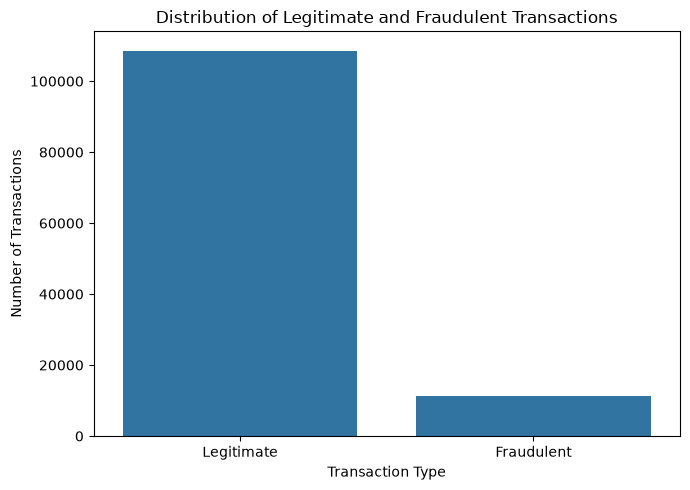

In [178]:
# Visualize legitimate vs fraudulent transactions

fraud_counts = df['is_fraud'].value_counts().sort_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=['Legitimate', 'Fraudulent'],
    y=fraud_counts.values
)

plt.title('Distribution of Legitimate and Fraudulent Transactions')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

In [13]:
fraud_percentage = (
    df['is_fraud'].value_counts(normalize=True) * 100
)

print(fraud_percentage)

is_fraud
0    90.510833
1     9.489167
Name: proportion, dtype: float64


In [14]:
# Inspect fraud categories
df['fraud_type'].value_counts()

fraud_type
Legitimate            108613
Card-Not-Present        2879
Account-Takeover        2571
Synthetic-Identity      2146
Card-Present            1898
Friendly-Fraud          1893
Name: count, dtype: int64

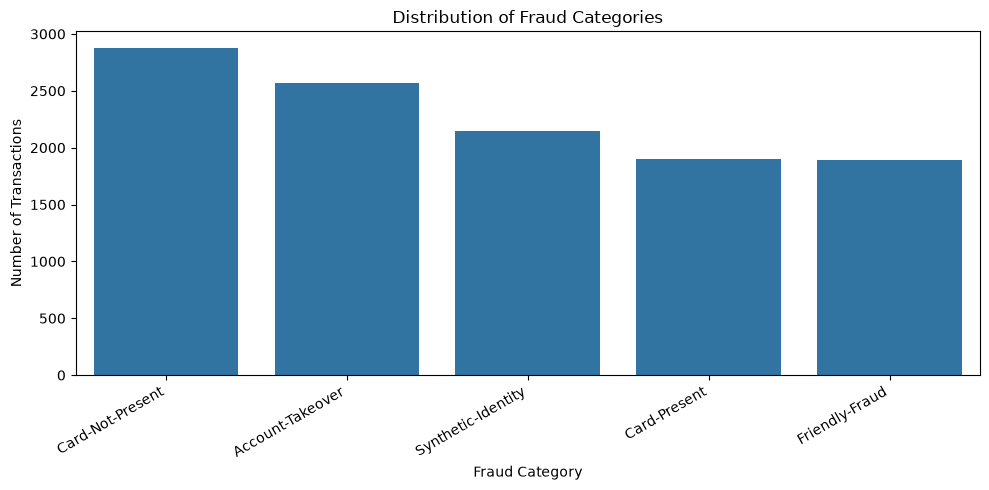

In [179]:
# Visualize distribution of fraud categories

fraud_category_counts = (
    df.loc[df['is_fraud'] == 1, 'fraud_type']
    .value_counts()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=fraud_category_counts.index,
    y=fraud_category_counts.values
)

plt.title('Distribution of Fraud Categories')
plt.xlabel('Fraud Category')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [15]:
# Convert transaction datetime into datetime format
df['transaction_datetime'] = pd.to_datetime(
    df['transaction_datetime'],
    errors='coerce'
)

# Check date range
print("Earliest Transaction:",
      df['transaction_datetime'].min())

print("Latest Transaction:",
      df['transaction_datetime'].max())

Earliest Transaction: 2026-01-01 00:00:00
Latest Transaction: 2026-06-30 23:58:00


In [16]:
# Inspect label availability
print(df['label_available'].value_counts())

label_available
1    108070
0     11930
Name: count, dtype: int64


In [17]:
# Inspect drift phases
print(df['drift_phase_name'].value_counts())

drift_phase_name
peak_drift               40586
stable_training          39133
pre_drift_validation     20445
partial_stabilization    19836
Name: count, dtype: int64


In [18]:
# Numerical columns
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

# Categorical columns
categorical_columns = df.select_dtypes(
    include=['object']
).columns

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['month', 'week_of_year', 'drift_phase', 'days_into_phase', 'drift_magnitude', 'transaction_amount', 'transaction_hour', 'card_present', 'customer_age', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velocity_24h', 'prior_dispute_ratio_90d', 'pos_entry_fallback', 'pin_retry_count_24h', 'concept_drift_score', 'population_shift_index', 'covariate_shift_flag', 'synthetic_id_camouflage_score', 'label_available', 'label_delay_da

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13172\1530337737.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


**Data Validation and Quality Checks**

In [19]:
# Check for negative values in selected columns

columns_to_check = [
    'transaction_amount',
    'credit_limit',
    'customer_age',
    'credit_score',
    'account_age_days',
    'transactions_last_1h',
    'transactions_last_24h',
    'transactions_last_7d',
    'distance_from_home_km',
    'distance_from_last_tx_km'
]

for col in columns_to_check:
    print(f"{col}: {(df[col] < 0).sum()} negative values")

transaction_amount: 0 negative values
credit_limit: 0 negative values
customer_age: 0 negative values
credit_score: 0 negative values
account_age_days: 0 negative values
transactions_last_1h: 0 negative values
transactions_last_24h: 0 negative values
transactions_last_7d: 0 negative values
distance_from_home_km: 0 negative values
distance_from_last_tx_km: 0 negative values


In [20]:
# Check binary columns
binary_columns = [
    'is_fraud',
    'card_present',
    'international_transaction',
    'high_risk_country',
    'used_chip',
    'used_pin',
    'is_weekend',
    'label_available',
    'pseudo_label',
    'dispute_filed'
]

for col in binary_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


is_fraud:
is_fraud
0    108613
1     11387
Name: count, dtype: int64

card_present:
card_present
0    61339
1    58661
Name: count, dtype: int64

international_transaction:
international_transaction
0    105819
1     14181
Name: count, dtype: int64

high_risk_country:
high_risk_country
0    112193
1      7807
Name: count, dtype: int64

used_chip:
used_chip
0    74754
1    45246
Name: count, dtype: int64

used_pin:
used_pin
0    81953
1    38047
Name: count, dtype: int64

is_weekend:
is_weekend
0    85685
1    34315
Name: count, dtype: int64

label_available:
label_available
1    108070
0     11930
Name: count, dtype: int64

pseudo_label:
pseudo_label
-1    108070
 0     10806
 1      1124
Name: count, dtype: int64

dispute_filed:
dispute_filed
0    117307
1      2693
Name: count, dtype: int64


In [21]:
# Check categorical consistency
categorical_columns = [
    'merchant_category',
    'merchant_country',
    'customer_gender',
    'customer_country',
    'transaction_channel',
    'device_type',
    'browser',
    'fraud_type',
    'drift_phase_name'
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


merchant_category:
merchant_category
retail             21324
grocery            19368
restaurant         16432
fuel               12811
electronics        10225
digital_goods       9837
subscription        9072
health              8456
travel              7608
cash_withdrawal     4867
Name: count, dtype: int64

merchant_country:
merchant_country
US    58166
IN    11569
GB    10622
CA     7531
DE     7170
FR     5393
IE     4587
ES     3802
NL     3177
SG     3111
NG     2723
BR     2149
Name: count, dtype: int64

customer_gender:
customer_gender
F          58506
M          55944
unknown     3294
X           2256
Name: count, dtype: int64

customer_country:
customer_country
US    48663
IN    14688
GB    12160
CA     7994
DE     6940
IE     6098
FR     5912
SG     3643
NG     3549
ES     3514
NL     3436
BR     3403
Name: count, dtype: int64

transaction_channel:
transaction_channel
POS           50226
ecommerce     35375
mobile_app    19942
ATM            8230
recurring      6227
Name

In [22]:
# Check date consistency
# Convert dispute-related dates

date_columns = [
    'dispute_event_datetime',
    'adjudication_datetime'
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Check invalid transaction dates
print("Missing transaction dates:",
      df['transaction_datetime'].isna().sum())

# Check dispute date relationships
disputed = df[df['dispute_filed'] == 1]

print(
    "Disputes with missing event dates:",
    disputed['dispute_event_datetime'].isna().sum()
)

print(
    "Disputes with missing adjudication dates:",
    disputed['adjudication_datetime'].isna().sum()
)

Missing transaction dates: 0
Disputes with missing event dates: 0
Disputes with missing adjudication dates: 0


In [23]:
# Compare fraud labels with fraud categories

pd.crosstab(
    df['is_fraud'],
    df['fraud_type'],
    margins=True
)

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Legitimate,Synthetic-Identity,All
is_fraud,,,,,,,
0,0,0,0,0,108613,0,108613
1,2571,2879,1898,1893,0,2146,11387
All,2571,2879,1898,1893,108613,2146,120000


In [24]:
# Check dispute date ordering
disputed = df[df['dispute_filed'] == 1].copy()

# Event date should not precede transaction date
print(
    "Event before transaction:",
    (disputed['dispute_event_datetime'] <
     disputed['transaction_datetime']).sum()
)

# Adjudication should not precede dispute event
print(
    "Adjudication before event:",
    (disputed['adjudication_datetime'] <
     disputed['dispute_event_datetime']).sum()
)

# Check dispute delay consistency
calculated_delay = (
    disputed['dispute_event_datetime'] -
    disputed['transaction_datetime']
).dt.total_seconds() / 86400

print(calculated_delay.describe())
print(disputed['dispute_delay_days'].describe())

Event before transaction: 0
Adjudication before event: 0
count    2693.000000
mean       30.857779
std        17.349079
min         1.000000
25%        16.000000
50%        31.000000
75%        46.000000
max        60.000000
dtype: float64
count    2693.000000
mean       30.857779
std        17.349079
min         1.000000
25%        16.000000
50%        31.000000
75%        46.000000
max        60.000000
Name: dispute_delay_days, dtype: float64


## 3. Outlier Analysis

In [25]:
# Identifying Outliers Using IQR Method
# Select numerical features for outlier analysis

outlier_columns = [
    'transaction_amount',
    'credit_limit',
    'credit_score',
    'distance_from_home_km',
    'distance_from_last_tx_km',
    'amount_vs_avg_ratio',
    'avg_transaction_amount_30d',
    'std_transaction_amount_30d'
]

# Calculate IQR and potential outlier boundaries

outlier_summary = []

for col in outlier_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary.append({
        'Column': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (
            len(outliers) / len(df)
        ) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,transaction_amount,-30.05000,110.67000,6581,5.484167
1,credit_limit,-4645.22125,16281.76875,6818,5.681667
2,credit_score,517.00000,861.00000,596,0.496667
3,distance_from_home_km,-19.09500,45.90500,9686,8.071667
4,distance_from_last_tx_km,-17.48000,40.36000,10649,8.874167
5,amount_vs_avg_ratio,-1.01420,2.95860,9974,8.311667
6,avg_transaction_amount_30d,28.57500,62.85500,28709,23.924167
7,std_transaction_amount_30d,-30.00000,50.00000,969,0.807500


**Outlier  Distribution by Fraud Status**

In [26]:
# Compare outlier percentages between legitimate and fraudulent transactions

comparison = []

for col in outlier_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify potential outliers
    outlier_flag = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    # Calculate outlier percentages by fraud status
    for fraud_status, group in df.groupby('is_fraud'):

        percentage = (
            outlier_flag.loc[group.index].sum() / len(group)
        ) * 100

        comparison.append({
            'Feature': col,
            'Fraud Status': (
                'Fraudulent' if fraud_status == 1 else 'Legitimate'
            ),
            'Outlier Count': outlier_flag.loc[group.index].sum(),
            'Outlier Percentage': percentage
        })

outlier_comparison = pd.DataFrame(comparison)

outlier_comparison

,Feature,Fraud Status,Outlier Count,Outlier Percentage
0,transaction_amount,Legitimate,4830,4.446981
1,transaction_amount,Fraudulent,1751,15.377185
2,credit_limit,Legitimate,6205,5.712944
3,credit_limit,Fraudulent,613,5.383332
4,credit_score,Legitimate,277,0.255034
5,credit_score,Fraudulent,319,2.801440
6,distance_from_home_km,Legitimate,8676,7.987994
7,distance_from_home_km,Fraudulent,1010,8.869764
8,distance_from_last_tx_km,Legitimate,8719,8.027584
9,distance_from_last_tx_km,Fraudulent,1930,16.949153


**Visualizing the Distributions**

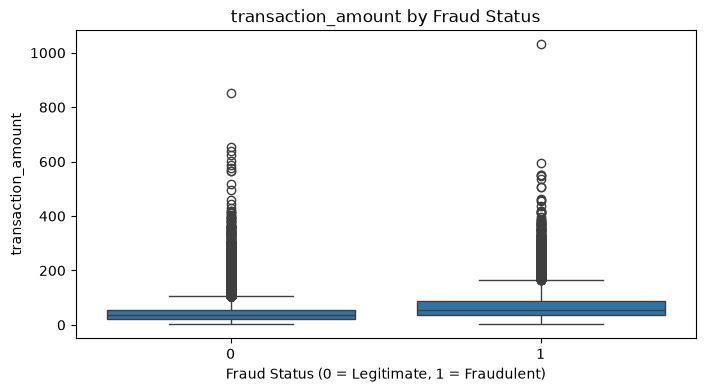

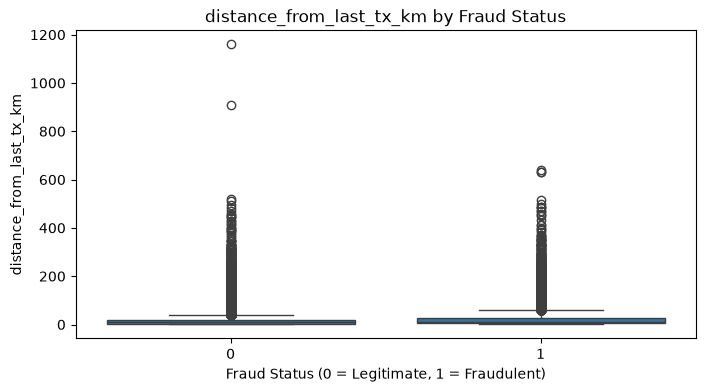

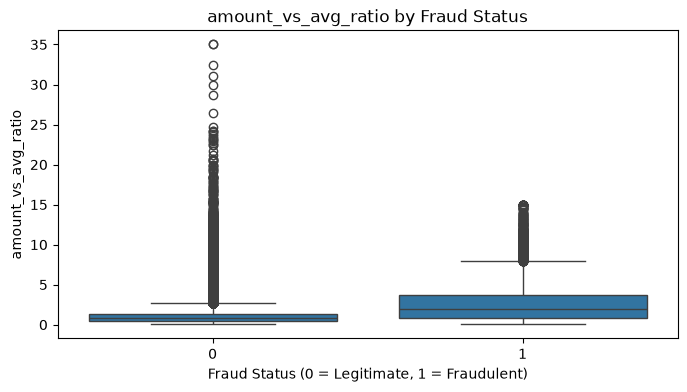

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

important_features = [
    'transaction_amount',
    'distance_from_last_tx_km',
    'amount_vs_avg_ratio'
]

for col in important_features:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x='is_fraud',
        y=col
    )

    plt.title(f'{col} by Fraud Status')
    plt.xlabel('Fraud Status (0 = Legitimate, 1 = Fraudulent)')
    plt.ylabel(col)

    plt.show()

**Descriptive  Statistics by Fraud Status**

In [28]:
important_features = [
    'transaction_amount',
    'distance_from_last_tx_km',
    'amount_vs_avg_ratio'
]

group_statistics = df.groupby('is_fraud')[important_features].describe()

group_statistics

transaction_amount                                             \
                      count       mean        std   min     25%    50%   
is_fraud                                                                 
0                  108613.0  43.887321  33.779891  1.50  22.030  34.87   
1                   11387.0  69.604877  54.064953  4.05  34.575  54.84   

                          distance_from_last_tx_km                        \
             75%      max                    count       mean        std   
is_fraud                                                                   
0         55.010   853.06                 108613.0  15.635756  23.330187   
1         87.315  1030.59                  11387.0  26.987646  44.722006   

                                            amount_vs_avg_ratio            \
           min   25%    50%    75%      max               count      mean   
is_fraud                                                                    
0         0.03  4.07   8.58  18.00  1159.35            108613.0  1.125506   
1         0.08  5.82  12.04  26.98   637.77             11387.0  2.664070   

                                                          
               std     min     25%     50%     75%   max  
is_fraud                                                  
0         1.273195  0.0200  0.4574  0.7718  1.3325  35.0  
1         2.380854  0.0548  0.8835  1.9290  3.7120  15.0

**Skewness  Analysis**

In [29]:
# Compare skewness by fraud status

skewness_analysis = df.groupby('is_fraud')[important_features].skew()

skewness_analysis

,transaction_amount,distance_from_last_tx_km,amount_vs_avg_ratio
is_fraud,,,
0,2.922395,6.850644,5.672892
1,2.832274,4.610726,1.670734


## 4. Missing Values, Potential Leakage and Dataset Metadata Checks

**Missing Value  Analysis**

In [30]:
# Calculate missing values in each column

missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

# Display only columns containing missing values

missing_summary = missing_summary[
    missing_summary['Missing Count'] > 0
].sort_values(by='Missing Percentage', ascending=False)

missing_summary

,Missing Count,Missing Percentage
dispute_delay_days,117307,97.755833
dispute_event_datetime,117307,97.755833
adjudication_datetime,117307,97.755833


**Potential Data Leakage Investigation**

In [31]:
# Identify potentially leakage-prone features

potential_leakage_columns = [
    'fraud_type',
    'pseudo_label',
    'post_transaction_outcome',
    'fraud_amount_lost',
    'dispute_delay_days',
    'dispute_event_datetime',
    'adjudication_datetime'
]

# Display their data types and sample values

for col in potential_leakage_columns:
    print(f"\nColumn: {col}")
    print("Data Type:", df[col].dtype)
    print("Sample Values:")
    print(df[col].dropna().head())


Column: fraud_type
Data Type: str
Sample Values:
0    Legitimate
1    Legitimate
2    Legitimate
3    Legitimate
4    Legitimate
Name: fraud_type, dtype: str

Column: pseudo_label
Data Type: int64
Sample Values:
0   -1
1   -1
2   -1
3   -1
4   -1
Name: pseudo_label, dtype: int64

Column: post_transaction_outcome
Data Type: int64
Sample Values:
0    0
1    0
2    0
3    0
4    0
Name: post_transaction_outcome, dtype: int64

Column: fraud_amount_lost
Data Type: float64
Sample Values:
0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: fraud_amount_lost, dtype: float64

Column: dispute_delay_days
Data Type: float64
Sample Values:
27     39.0
117    28.0
124    41.0
160    23.0
328     7.0
Name: dispute_delay_days, dtype: float64

Column: dispute_event_datetime
Data Type: datetime64[us]
Sample Values:
27    2026-02-09 00:49:00
117   2026-01-29 04:16:00
124   2026-02-11 04:30:00
160   2026-01-24 05:50:00
328   2026-01-08 12:28:00
Name: dispute_event_datetime, dtype: datetime64[us]

Column: 

In [32]:
# Examine pseudo-label distribution by actual fraud status

pd.crosstab(
    df['pseudo_label'],
    df['is_fraud'],
    margins=True
)

is_fraud,0,1,All
pseudo_label,,,
-1,97864,10206,108070
0,9798,1008,10806
1,951,173,1124
All,108613,11387,120000


In [33]:
pd.crosstab(
    df['pseudo_label'],
    df['is_fraud'],
    normalize='index'
) * 100

is_fraud,0,1
pseudo_label,,
-1,90.556121,9.443879
0,90.671849,9.328151
1,84.608541,15.391459


In [34]:
pd.crosstab(
    df['post_transaction_outcome'],
    df['is_fraud'],
    margins=True
)

is_fraud,0,1,All
post_transaction_outcome,,,
0,108613,10860,119473
1,0,527,527
All,108613,11387,120000


In [35]:
df.groupby('is_fraud')['fraud_amount_lost'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,108613.0,0.000000,0.000000,0.00,0.000,0.00,0.000,0.0
1,11387.0,45.269254,38.038775,1.94,20.575,34.33,57.405,504.8


In [36]:
pd.crosstab(
    df['dispute_filed'],
    df['is_fraud'],
    margins=True
)

is_fraud,0,1,All
dispute_filed,,,
0,106932,10375,117307
1,1681,1012,2693
All,108613,11387,120000


In [37]:
pd.crosstab(
    df['dispute_filed'],
    df['is_fraud'],
    normalize='index'
) * 100

is_fraud,0,1
dispute_filed,,
0,91.155686,8.844314
1,62.421092,37.578908


In [38]:
dispute_columns = [
    'dispute_delay_days',
    'dispute_event_datetime',
    'adjudication_datetime'
]

df[dispute_columns].describe(include='all')

,dispute_delay_days,dispute_event_datetime,adjudication_datetime
count,2693.000000,2693,2693
mean,30.857779,2026-05-02 14:48:12.387671,2026-05-18 00:41:12.632751
min,1.000000,2026-01-05 02:15:00,2026-01-07 02:15:00
25%,16.000000,2026-03-18 04:12:00,2026-04-01 09:41:00
50%,31.000000,2026-05-02 16:27:00,2026-05-19 07:09:00
75%,46.000000,2026-06-17 16:57:00,2026-07-02 10:58:00
max,60.000000,2026-08-25 01:00:00,2026-09-14 09:02:00
std,17.349079,NaN,NaN


In [39]:
exclude_columns = [
    'fraud_type',
    'pseudo_label',
    'post_transaction_outcome',
    'fraud_amount_lost',
    'dispute_filed',
    'dispute_delay_days',
    'dispute_event_datetime',
    'adjudication_datetime'
]

print("Columns excluded from model predictors:")
for col in exclude_columns:
    print("-", col)

print("\nTotal excluded columns:", len(exclude_columns))

Columns excluded from model predictors:
- fraud_type
- pseudo_label
- post_transaction_outcome
- fraud_amount_lost
- dispute_filed
- dispute_delay_days
- dispute_event_datetime
- adjudication_datetime

Total excluded columns: 8


In [40]:
# Check the remaining features
remaining_columns = [
    col for col in df.columns
    if col not in exclude_columns
]

print("Original number of columns:", df.shape[1])
print("Excluded columns:", len(exclude_columns))
print("Remaining columns:", len(remaining_columns))

Original number of columns: 73
Excluded columns: 8
Remaining columns: 65


In [41]:
# Identify the remaining columns
for i, col in enumerate(remaining_columns, start=1):
    print(i, col)

1 transaction_id
2 customer_id
3 card_id
4 merchant_id
5 transaction_datetime
6 month
7 week_of_year
8 drift_phase
9 days_into_phase
10 drift_magnitude
11 transaction_amount
12 merchant_category
13 merchant_country
14 transaction_hour
15 transaction_day_of_week
16 card_present
17 customer_age
18 customer_gender
19 customer_country
20 account_age_days
21 credit_limit
22 credit_score
23 num_cards_held
24 transactions_last_1h
25 transactions_last_24h
26 transactions_last_7d
27 amount_last_1h
28 amount_last_24h
29 days_since_last_transaction
30 distance_from_home_km
31 distance_from_last_tx_km
32 international_transaction
33 high_risk_country
34 amount_vs_avg_ratio
35 used_chip
36 used_pin
37 transaction_channel
38 device_type
39 browser
40 is_weekend
41 avg_transaction_amount_30d
42 std_transaction_amount_30d
43 num_declined_last_30d
44 num_chargebacks_ever
45 email_domain
46 failed_auth_attempts_24h
47 device_change_7d
48 billing_shipping_mismatch
49 account_profile_change_7d
50 merchant

In [42]:
pd.crosstab(
    df['transaction_time_target'],
    df['is_fraud'],
    margins=True
)

is_fraud,0,1,All
transaction_time_target,,,
Account-Takeover,0,2571,2571
Card-Not-Present,0,2879,2879
Card-Present,0,1898,1898
EXCLUDE_POST_TRANSACTION,0,1893,1893
Legitimate,108613,0,108613
Synthetic-Identity,0,2146,2146
All,108613,11387,120000


In [43]:
pd.crosstab(
    df['dispute_adjudicated_friendly_fraud'],
    df['is_fraud'],
    margins=True
)

is_fraud,0,1,All
dispute_adjudicated_friendly_fraud,,,
0,108200,10780,118980
1,413,607,1020
All,108613,11387,120000


In [44]:
pd.crosstab(
    df['dispute_adjudicated_friendly_fraud'],
    df['is_fraud'],
    normalize='index'
) * 100

is_fraud,0,1
dispute_adjudicated_friendly_fraud,,
0,90.939654,9.060346
1,40.490196,59.509804


In [45]:
pd.crosstab(
    df['label_available'],
    df['is_fraud'],
    margins=True
)

is_fraud,0,1,All
label_available,,,
0,10749,1181,11930
1,97864,10206,108070
All,108613,11387,120000


In [46]:
df.groupby('label_available')['label_delay_days'].describe()

,count,mean,std,min,25%,50%,75%,max
label_available,,,,,,,,
0,11930.0,22.934367,12.057758,7.0,14.0,21.0,30.0,45.0
1,108070.0,10.575433,13.589151,0.0,0.0,1.0,21.0,45.0


In [47]:
pd.crosstab(
    df['transaction_time_eligible'],
    df['is_fraud'],
    margins=True
)

is_fraud,0,1,All
transaction_time_eligible,,,
0,0,1893,1893
1,108613,9494,118107
All,108613,11387,120000


In [48]:
drift_columns = [
    'drift_phase',
    'drift_phase_name',
    'dispute_regime'
]

for col in drift_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


drift_phase
drift_phase
3    40586
1    39133
2    20445
4    19836
Name: count, dtype: int64

drift_phase_name
drift_phase_name
peak_drift               40586
stable_training          39133
pre_drift_validation     20445
partial_stabilization    19836
Name: count, dtype: int64

dispute_regime
dispute_regime
later_period    60422
early_period    59578
Name: count, dtype: int64


In [49]:
# Check whether the two drift columns match row by row
pd.crosstab(
    df['drift_phase'],
    df['drift_phase_name']
)

drift_phase_name,partial_stabilization,peak_drift,pre_drift_validation,stable_training
drift_phase,,,,
1,0,0,0,39133
2,0,0,20445,0
3,0,40586,0,0
4,19836,0,0,0


In [50]:
pd.crosstab(
    df['dispute_regime'],
    df['is_fraud'],
    margins=True
)

is_fraud,0,1,All
dispute_regime,,,
early_period,53956,5622,59578
later_period,54657,5765,60422
All,108613,11387,120000


In [51]:
drift_numeric_columns = [
    'days_into_phase',
    'drift_magnitude',
    'concept_drift_score',
    'population_shift_index',
    'covariate_shift_flag'
]

df[drift_numeric_columns].describe()

,days_into_phase,drift_magnitude,concept_drift_score,population_shift_index,covariate_shift_flag
count,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000
mean,24.584083,0.316672,0.323744,0.308713,0.453533
std,16.560963,0.326347,0.321033,0.239417,0.497838
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,11.000000,0.000000,0.000400,0.080700,0.000000
50%,22.000000,0.480000,0.408450,0.325250,0.000000
75%,37.000000,0.620000,0.623000,0.531300,1.000000
max,60.000000,0.780000,0.919100,0.825700,1.000000


In [52]:
# Compare drift features with the fraud target
df.groupby('is_fraud')[drift_numeric_columns].mean().T

is_fraud,0,1
days_into_phase,24.562189,24.792922
drift_magnitude,0.316517,0.318143
concept_drift_score,0.323602,0.325103
population_shift_index,0.308598,0.309809
covariate_shift_flag,0.453500,0.453851


In [53]:
# Investigate the synthetic ID feature
df.groupby('is_fraud')['synthetic_id_camouflage_score'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,108613.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0000
1,11387.0,0.030306,0.098127,0.0,0.0,0.0,0.0,0.7251


In [54]:
df.groupby('is_fraud')['synthetic_id_camouflage_score'].apply(
    lambda x: (x > 0).sum()
)

is_fraud
0       0
1    1156
Name: synthetic_id_camouflage_score, dtype: int64

In [55]:
df[['transaction_id', 'customer_id', 'card_id', 'merchant_id']].nunique()

transaction_id    120000
customer_id        29441
card_id            29441
merchant_id         5000
dtype: int64

## 5. Dataset Structure, Entity Relationships and Temporal Patterns

In [56]:
# Customer-card relationship
df.groupby('customer_id')['card_id'].nunique().value_counts()

card_id
1    29441
Name: count, dtype: int64

In [57]:
# Merchant transaction distribution
df['merchant_id'].value_counts().describe()

count    5000.000000
mean       24.000000
std         4.929022
min         8.000000
25%        21.000000
50%        24.000000
75%        27.000000
max        44.000000
Name: count, dtype: float64

In [58]:
# Check customer transaction distribution
df['customer_id'].value_counts().describe()

count    29441.000000
mean         4.075949
std          1.934036
min          1.000000
25%          3.000000
50%          4.000000
75%          5.000000
max         15.000000
Name: count, dtype: float64

In [59]:
# Check transaction ID patterns
df['transaction_id'].head(10)

0    TX4042000000000
1    TX4042000000001
2    TX4042000000002
3    TX4042000000003
4    TX4042000000004
5    TX4042000000005
6    TX4042000000006
7    TX4042000000007
8    TX4042000000008
9    TX4042000000009
Name: transaction_id, dtype: str

In [60]:
# Inspect the date and time features
df[['transaction_datetime', 'month', 'week_of_year',
    'transaction_hour', 'transaction_day_of_week']].head(10)

,transaction_datetime,month,week_of_year,transaction_hour,transaction_day_of_week
0,2026-01-01 00:00:00,1,1,0,Thursday
1,2026-01-01 00:00:00,1,1,0,Thursday
2,2026-01-01 00:03:00,1,1,0,Thursday
3,2026-01-01 00:04:00,1,1,0,Thursday
4,2026-01-01 00:05:00,1,1,0,Thursday
5,2026-01-01 00:05:00,1,1,0,Thursday
6,2026-01-01 00:05:00,1,1,0,Thursday
7,2026-01-01 00:07:00,1,1,0,Thursday
8,2026-01-01 00:11:00,1,1,0,Thursday
9,2026-01-01 00:12:00,1,1,0,Thursday


In [61]:
# Validate the extracted temporal features
temporal_check = pd.DataFrame({
    'month_match': (
        df['month'] == df['transaction_datetime'].dt.month
    ),
    'hour_match': (
        df['transaction_hour'] == df['transaction_datetime'].dt.hour
    ),
    'day_match': (
        df['transaction_day_of_week'] ==
        df['transaction_datetime'].dt.day_name()
    )
})

temporal_check.sum()

month_match    120000
hour_match     120000
day_match      120000
dtype: int64

In [62]:
# Validate week_of_year
df[['transaction_datetime', 'week_of_year']].assign(
    calculated_week=df['transaction_datetime'].dt.isocalendar().week
).head(15)

,transaction_datetime,week_of_year,calculated_week
0,2026-01-01 00:00:00,1,1
1,2026-01-01 00:00:00,1,1
2,2026-01-01 00:03:00,1,1
3,2026-01-01 00:04:00,1,1
4,2026-01-01 00:05:00,1,1
5,2026-01-01 00:05:00,1,1
6,2026-01-01 00:05:00,1,1
7,2026-01-01 00:07:00,1,1
8,2026-01-01 00:11:00,1,1
9,2026-01-01 00:12:00,1,1


In [63]:
week_match = (
    df['week_of_year'] ==
    df['transaction_datetime'].dt.isocalendar().week
)

week_match.value_counts()

True    120000
Name: count, dtype: Int64

In [64]:
# Examine transaction-hour distribution
df['transaction_hour'].value_counts().sort_index()

transaction_hour
0     5078
1     4974
2     5047
3     4915
4     5090
5     4950
6     5014
7     4999
8     5070
9     5162
10    4990
11    4972
12    4969
13    5001
14    5051
15    5020
16    4911
17    5095
18    4955
19    5007
20    4936
21    4899
22    4949
23    4946
Name: count, dtype: int64

In [65]:
# Compare transaction hours by fraud status
df.groupby('transaction_hour')['is_fraud'].mean().mul(100).round(2)

transaction_hour
0      9.47
1     10.70
2      9.97
3      9.62
4      9.12
5      9.52
6      9.05
7      9.24
8      9.57
9      9.49
10     9.08
11     9.37
12     9.62
13     9.20
14     9.76
15     8.84
16     9.33
17    10.32
18    10.21
19     8.75
20     9.50
21     9.04
22     9.46
23     9.50
Name: is_fraud, dtype: float64

In [66]:
# Analyze weekday transaction distribution
df['transaction_day_of_week'].value_counts()

transaction_day_of_week
Tuesday      17465
Thursday     17358
Sunday       17249
Monday       17190
Friday       17078
Saturday     17066
Wednesday    16594
Name: count, dtype: int64

In [67]:
# Compare weekday fraud rates
df.groupby('transaction_day_of_week')['is_fraud'].mean().mul(100).round(2)

transaction_day_of_week
Friday       9.31
Monday       9.45
Saturday     9.70
Sunday       9.45
Thursday     9.29
Tuesday      9.69
Wednesday    9.53
Name: is_fraud, dtype: float64

In [68]:
# Compare weekdays and weekends
df.groupby('is_weekend')['is_fraud'].agg(
    transaction_count='count',
    fraud_count='sum',
    fraud_rate='mean'
).assign(
    fraud_rate=lambda x: (x['fraud_rate'] * 100).round(2)
)

,transaction_count,fraud_count,fraud_rate
is_weekend,,,
0,85685,8101,9.45
1,34315,3286,9.58


In [69]:
# Investigate monthly transaction distribution
df['month'].value_counts().sort_index()

month
1    20521
2    18612
3    20445
4    19861
5    20725
6    19836
Name: count, dtype: int64

In [70]:
# Compare monthly fraud rates
df.groupby('month')['is_fraud'].agg(
    transaction_count='count',
    fraud_count='sum',
    fraud_rate='mean'
).assign(
    fraud_rate=lambda x: (x['fraud_rate'] * 100).round(2)
)

,transaction_count,fraud_count,fraud_rate
month,,,
1,20521,1909,9.30
2,18612,1808,9.71
3,20445,1905,9.32
4,19861,1870,9.42
5,20725,1979,9.55
6,19836,1916,9.66


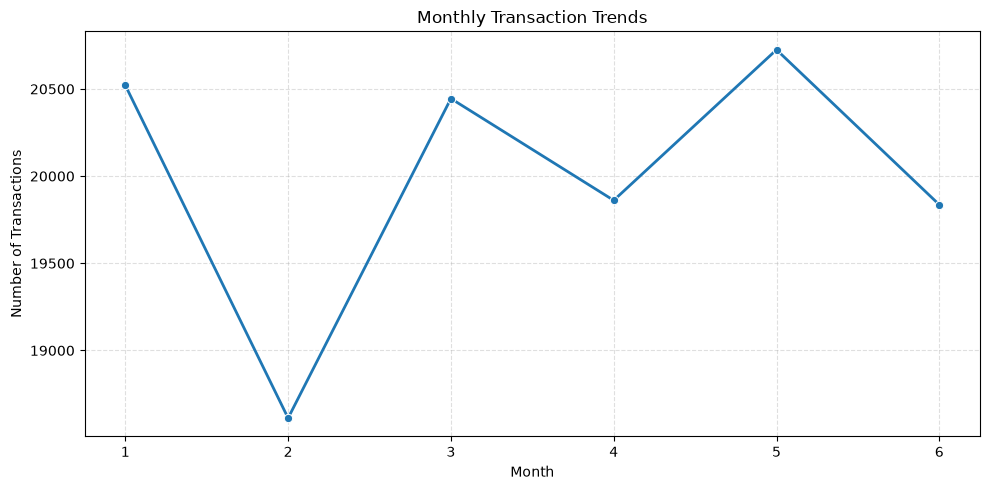

In [180]:
# Visualize monthly transaction trends

monthly_transactions = (
    df.groupby('month')
    .size()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_transactions.index,
    y=monthly_transactions.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Transaction Trends')
plt.xlabel('Month')
plt.ylabel('Number of Transactions')
plt.xticks(range(1, 7))
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [71]:
# Investigate the relationship with drift phases
df.groupby('drift_phase_name')['is_fraud'].agg(
    transaction_count='count',
    fraud_count='sum',
    fraud_rate='mean'
).assign(
    fraud_rate=lambda x: (x['fraud_rate'] * 100).round(2)
)

,transaction_count,fraud_count,fraud_rate
drift_phase_name,,,
partial_stabilization,19836,1916,9.66
peak_drift,40586,3849,9.48
pre_drift_validation,20445,1905,9.32
stable_training,39133,3717,9.50


In [72]:
# Investigate the actual date range of each drift phase
df.groupby('drift_phase_name')['transaction_datetime'].agg(
    start_date='min',
    end_date='max',
    transaction_count='count'
)

,start_date,end_date,transaction_count
drift_phase_name,,,
partial_stabilization,2026-06-01 00:05:00,2026-06-30 23:58:00,19836
peak_drift,2026-04-01 00:04:00,2026-05-31 23:57:00,40586
pre_drift_validation,2026-03-01 00:02:00,2026-03-31 23:58:00,20445
stable_training,2026-01-01 00:00:00,2026-02-28 23:59:00,39133


In [73]:
# Investigate days_into_phase
phase_start_dates = {
    'stable_training': pd.Timestamp('2026-01-01'),
    'pre_drift_validation': pd.Timestamp('2026-03-01'),
    'peak_drift': pd.Timestamp('2026-04-01'),
    'partial_stabilization': pd.Timestamp('2026-06-01')
}

expected_days = (
    df['transaction_datetime'] -
    df['drift_phase_name'].map(phase_start_dates)
).dt.days

(expected_days == df['days_into_phase']).value_counts()

True    120000
Name: count, dtype: int64

In [74]:
# Investigate dispute_regime
df.groupby('dispute_regime')['transaction_datetime'].agg(
    start_date='min',
    end_date='max',
    transaction_count='count'
)

,start_date,end_date,transaction_count
dispute_regime,,,
early_period,2026-01-01 00:00:00,2026-03-31 23:58:00,59578
later_period,2026-04-01 00:04:00,2026-06-30 23:58:00,60422


In [75]:
# Check fraud distribution across dispute regimes
regime_fraud = df.groupby('dispute_regime')['is_fraud'].agg(
    transaction_count='count',
    fraud_count='sum',
    fraud_rate='mean'
)

regime_fraud['fraud_rate'] = regime_fraud['fraud_rate'] * 100

regime_fraud

,transaction_count,fraud_count,fraud_rate
dispute_regime,,,
early_period,59578,5622,9.436369
later_period,60422,5765,9.541227


In [76]:
df.groupby(['fraud_type'])['synthetic_id_camouflage_score'].agg(
    transaction_count='count',
    non_zero_count=lambda x: (x > 0).sum(),
    mean_score='mean',
    max_score='max'
)

,transaction_count,non_zero_count,mean_score,max_score
fraud_type,,,,
Account-Takeover,2571,0,0.000000,0.0000
Card-Not-Present,2879,0,0.000000,0.0000
Card-Present,1898,0,0.000000,0.0000
Friendly-Fraud,1893,0,0.000000,0.0000
Legitimate,108613,0,0.000000,0.0000
Synthetic-Identity,2146,1156,0.160806,0.7251


In [77]:
# Investigate the score's distribution
df.loc[
    df['synthetic_id_camouflage_score'] > 0,
    'synthetic_id_camouflage_score'
].describe()

count    1156.000000
mean        0.298521
std         0.121595
min         0.036900
25%         0.207375
50%         0.281350
75%         0.377800
max         0.725100
Name: synthetic_id_camouflage_score, dtype: float64

In [78]:
# Investigate transaction_time_eligible
pd.crosstab(
    df['transaction_time_eligible'],
    df['fraud_type'],
    margins=True
)

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Legitimate,Synthetic-Identity,All
transaction_time_eligible,,,,,,,
0,0,0,0,1893,0,0,1893
1,2571,2879,1898,0,108613,2146,118107
All,2571,2879,1898,1893,108613,2146,120000


In [79]:
# Investigate post_transaction_outcome
pd.crosstab(
    df['post_transaction_outcome'],
    df['fraud_type'],
    margins=True
)

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Legitimate,Synthetic-Identity,All
post_transaction_outcome,,,,,,,
0,2571,2879,1898,1366,108613,2146,119473
1,0,0,0,527,0,0,527
All,2571,2879,1898,1893,108613,2146,120000


In [80]:
# Investigate dispute_adjudicated_friendly_fraud
pd.crosstab(
    df['dispute_adjudicated_friendly_fraud'],
    df['fraud_type'],
    margins=True
)

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Legitimate,Synthetic-Identity,All
dispute_adjudicated_friendly_fraud,,,,,,,
0,2552,2838,1894,1366,108200,2130,118980
1,19,41,4,527,413,16,1020
All,2571,2879,1898,1893,108613,2146,120000


In [81]:
# Verify the relationship at row level
pd.crosstab(
    df['post_transaction_outcome'],
    df['dispute_adjudicated_friendly_fraud'],
    margins=True
)

dispute_adjudicated_friendly_fraud,0,1,All
post_transaction_outcome,,,
0,118980,493,119473
1,0,527,527
All,118980,1020,120000


In [82]:
# Investigate label_available
pd.crosstab(
    df['label_available'],
    df['fraud_type'],
    margins=True
)

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Legitimate,Synthetic-Identity,All
label_available,,,,,,,
0,280,292,179,185,10749,245,11930
1,2291,2587,1719,1708,97864,1901,108070
All,2571,2879,1898,1893,108613,2146,120000


In [83]:
# Investigate label_delay_days
df.groupby('label_available')['label_delay_days'].describe()

,count,mean,std,min,25%,50%,75%,max
label_available,,,,,,,,
0,11930.0,22.934367,12.057758,7.0,14.0,21.0,30.0,45.0
1,108070.0,10.575433,13.589151,0.0,0.0,1.0,21.0,45.0


In [84]:
# Investigate pseudo_label
pd.crosstab(
    df['pseudo_label'],
    df['fraud_type'],
    margins=True
)

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Legitimate,Synthetic-Identity,All
pseudo_label,,,,,,,
-1,2291,2587,1719,1708,97864,1901,108070
0,216,241,161,170,9798,220,10806
1,64,51,18,15,951,25,1124
All,2571,2879,1898,1893,108613,2146,120000


In [85]:
# Compare pseudo_label with label_available
pd.crosstab(
    df['pseudo_label'],
    df['label_available'],
    margins=True
)

label_available,0,1,All
pseudo_label,,,
-1,0,108070,108070
0,10806,0,10806
1,1124,0,1124
All,11930,108070,120000


In [86]:
# Investigate transaction_time_target
pd.crosstab(
    df['transaction_time_target'],
    df['fraud_type'],
    margins=True
)

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Legitimate,Synthetic-Identity,All
transaction_time_target,,,,,,,
Account-Takeover,2571,0,0,0,0,0,2571
Card-Not-Present,0,2879,0,0,0,0,2879
Card-Present,0,0,1898,0,0,0,1898
EXCLUDE_POST_TRANSACTION,0,0,0,1893,0,0,1893
Legitimate,0,0,0,0,108613,0,108613
Synthetic-Identity,0,0,0,0,0,2146,2146
All,2571,2879,1898,1893,108613,2146,120000


In [87]:
# Investigate fraud_amount_lost
df.groupby('fraud_type')['fraud_amount_lost'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud_type,,,,,,,,
Account-Takeover,2571.0,52.102645,42.664246,1.94,23.9650,39.64,65.0600,474.96
Card-Not-Present,2879.0,47.913025,40.248956,3.81,21.8050,36.15,60.2850,423.81
Card-Present,1898.0,36.850558,30.188349,2.44,17.1825,28.07,46.6700,251.57
Friendly-Fraud,1893.0,40.843671,32.473862,2.08,18.6300,31.44,53.0100,250.88
Legitimate,108613.0,0.000000,0.000000,0.00,0.0000,0.00,0.0000,0.00
Synthetic-Identity,2146.0,44.885401,38.007117,3.04,20.9950,34.85,56.5025,504.80


In [88]:
# Investigate dispute_filed
pd.crosstab(
    df['dispute_filed'],
    df['fraud_type'],
    margins=True
)

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Legitimate,Synthetic-Identity,All
dispute_filed,,,,,,,
0,2519,2794,1868,1106,106932,2088,117307
1,52,85,30,787,1681,58,2693
All,2571,2879,1898,1893,108613,2146,120000


In [89]:
df.groupby('fraud_type')['dispute_delay_days'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud_type,,,,,,,,
Account-Takeover,52.0,28.903846,18.830784,1.0,14.50,26.0,46.25,60.0
Card-Not-Present,85.0,30.705882,17.882436,1.0,15.00,31.0,47.00,60.0
Card-Present,30.0,26.700000,16.919994,1.0,13.25,24.5,40.75,56.0
Friendly-Fraud,787.0,30.564168,17.351680,1.0,15.00,31.0,45.00,60.0
Legitimate,1681.0,31.071386,17.273732,1.0,17.00,31.0,46.00,60.0
Synthetic-Identity,58.0,32.775862,17.775444,1.0,18.00,35.0,47.75,58.0


In [90]:
# investigate dispute_event_datetime across fraud categories
df.groupby('fraud_type')['dispute_event_datetime'].agg(
    ['count', 'min', 'max']
)

,count,min,max
fraud_type,,,
Account-Takeover,52,2026-01-13 15:00:00,2026-08-20 06:35:00
Card-Not-Present,85,2026-01-07 18:11:00,2026-08-21 04:22:00
Card-Present,30,2026-01-15 04:18:00,2026-07-11 17:03:00
Friendly-Fraud,787,2026-01-05 02:15:00,2026-08-25 01:00:00
Legitimate,1681,2026-01-05 12:23:00,2026-08-24 23:49:00
Synthetic-Identity,58,2026-01-07 01:05:00,2026-08-10 20:03:00


In [91]:
# Investigate adjudication_datetime
df.groupby('fraud_type')['adjudication_datetime'].agg(
    ['count', 'min', 'max']
)

,count,min,max
fraud_type,,,
Account-Takeover,52,2026-02-01 15:00:00,2026-08-25 03:07:00
Card-Not-Present,85,2026-01-13 10:37:00,2026-09-14 04:22:00
Card-Present,30,2026-02-03 06:25:00,2026-07-23 17:03:00
Friendly-Fraud,787,2026-01-07 02:15:00,2026-09-14 09:02:00
Legitimate,1681,2026-01-13 18:42:00,2026-09-14 06:24:00
Synthetic-Identity,58,2026-01-25 18:44:00,2026-08-26 20:03:00


In [92]:
# investigate dispute_adjudicated_friendly_fraud
pd.crosstab(
    df['fraud_type'],
    df['dispute_adjudicated_friendly_fraud'],
    margins=True
)

dispute_adjudicated_friendly_fraud,0,1,All
fraud_type,,,
Account-Takeover,2552,19,2571
Card-Not-Present,2838,41,2879
Card-Present,1894,4,1898
Friendly-Fraud,1366,527,1893
Legitimate,108200,413,108613
Synthetic-Identity,2130,16,2146
All,118980,1020,120000


## 6. Target, Label, Dispute and Drift Metadata Investigation

In [93]:
# investigate transaction_time_eligible
pd.crosstab(
    df['fraud_type'],
    df['transaction_time_eligible'],
    margins=True
)

transaction_time_eligible,0,1,All
fraud_type,,,
Account-Takeover,0,2571,2571
Card-Not-Present,0,2879,2879
Card-Present,0,1898,1898
Friendly-Fraud,1893,0,1893
Legitimate,0,108613,108613
Synthetic-Identity,0,2146,2146
All,1893,118107,120000


In [94]:
df.groupby('fraud_type')['synthetic_id_camouflage_score'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud_type,,,,,,,,
Account-Takeover,2571.0,0.000000,0.000000,0.0,0.0,0.0000,0.000000,0.0000
Card-Not-Present,2879.0,0.000000,0.000000,0.0,0.0,0.0000,0.000000,0.0000
Card-Present,1898.0,0.000000,0.000000,0.0,0.0,0.0000,0.000000,0.0000
Friendly-Fraud,1893.0,0.000000,0.000000,0.0,0.0,0.0000,0.000000,0.0000
Legitimate,108613.0,0.000000,0.000000,0.0,0.0,0.0000,0.000000,0.0000
Synthetic-Identity,2146.0,0.160806,0.173542,0.0,0.0,0.1426,0.291575,0.7251


In [95]:
# Investigate pseudo_label
pd.crosstab(
    df['fraud_type'],
    df['pseudo_label'],
    margins=True
)

pseudo_label,-1,0,1,All
fraud_type,,,,
Account-Takeover,2291,216,64,2571
Card-Not-Present,2587,241,51,2879
Card-Present,1719,161,18,1898
Friendly-Fraud,1708,170,15,1893
Legitimate,97864,9798,951,108613
Synthetic-Identity,1901,220,25,2146
All,108070,10806,1124,120000


In [96]:
# Investigate post_transaction_outcome
pd.crosstab(
    df['fraud_type'],
    df['post_transaction_outcome'],
    margins=True
)

post_transaction_outcome,0,1,All
fraud_type,,,
Account-Takeover,2571,0,2571
Card-Not-Present,2879,0,2879
Card-Present,1898,0,1898
Friendly-Fraud,1366,527,1893
Legitimate,108613,0,108613
Synthetic-Identity,2146,0,2146
All,119473,527,120000


In [97]:
# Investigate transaction_time_target
pd.crosstab(
    df['fraud_type'],
    df['transaction_time_target'],
    margins=True
)

transaction_time_target,Account-Takeover,Card-Not-Present,Card-Present,EXCLUDE_POST_TRANSACTION,Legitimate,Synthetic-Identity,All
fraud_type,,,,,,,
Account-Takeover,2571,0,0,0,0,0,2571
Card-Not-Present,0,2879,0,0,0,0,2879
Card-Present,0,0,1898,0,0,0,1898
Friendly-Fraud,0,0,0,1893,0,0,1893
Legitimate,0,0,0,0,108613,0,108613
Synthetic-Identity,0,0,0,0,0,2146,2146
All,2571,2879,1898,1893,108613,2146,120000


In [98]:
# Investigate drift metadata
pd.crosstab(
    df['fraud_type'],
    df['drift_phase_name'],
    margins=True
)

drift_phase_name,partial_stabilization,peak_drift,pre_drift_validation,stable_training,All
fraud_type,,,,,
Account-Takeover,467,862,429,813,2571
Card-Not-Present,477,938,501,963,2879
Card-Present,310,623,355,610,1898
Friendly-Fraud,291,641,304,657,1893
Legitimate,17920,36737,18540,35416,108613
Synthetic-Identity,371,785,316,674,2146
All,19836,40586,20445,39133,120000


In [99]:
# Investigate days_into_phase
df.groupby('fraud_type')['days_into_phase'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud_type,,,,,,,,
Account-Takeover,2571.0,24.831583,16.873206,0.0,11.0,22.0,38.0,60.0
Card-Not-Present,2879.0,24.450156,16.512158,0.0,11.0,22.0,37.0,60.0
Card-Present,1898.0,25.005796,16.838890,0.0,11.0,23.0,39.0,60.0
Friendly-Fraud,1893.0,24.910724,16.369348,0.0,12.0,23.0,37.0,60.0
Legitimate,108613.0,24.562189,16.553707,0.0,11.0,22.0,37.0,60.0
Synthetic-Identity,2146.0,24.914259,16.540974,0.0,11.0,23.0,38.0,60.0


In [100]:
# Investigate drift_phase
pd.crosstab(
    df['fraud_type'],
    df['drift_phase'],
    margins=True
)

drift_phase,1,2,3,4,All
fraud_type,,,,,
Account-Takeover,813,429,862,467,2571
Card-Not-Present,963,501,938,477,2879
Card-Present,610,355,623,310,1898
Friendly-Fraud,657,304,641,291,1893
Legitimate,35416,18540,36737,17920,108613
Synthetic-Identity,674,316,785,371,2146
All,39133,20445,40586,19836,120000


In [101]:
# Investigate dispute_regime
pd.crosstab(
    df['fraud_type'],
    df['dispute_regime'],
    margins=True
)

dispute_regime,early_period,later_period,All
fraud_type,,,
Account-Takeover,1242,1329,2571
Card-Not-Present,1464,1415,2879
Card-Present,965,933,1898
Friendly-Fraud,961,932,1893
Legitimate,53956,54657,108613
Synthetic-Identity,990,1156,2146
All,59578,60422,120000


In [102]:
# Check the remaining columns
df.columns.tolist()

['transaction_id',
 'customer_id',
 'card_id',
 'merchant_id',
 'transaction_datetime',
 'month',
 'week_of_year',
 'drift_phase',
 'days_into_phase',
 'drift_magnitude',
 'transaction_amount',
 'merchant_category',
 'merchant_country',
 'transaction_hour',
 'transaction_day_of_week',
 'card_present',
 'customer_age',
 'customer_gender',
 'customer_country',
 'account_age_days',
 'credit_limit',
 'credit_score',
 'num_cards_held',
 'transactions_last_1h',
 'transactions_last_24h',
 'transactions_last_7d',
 'amount_last_1h',
 'amount_last_24h',
 'days_since_last_transaction',
 'distance_from_home_km',
 'distance_from_last_tx_km',
 'international_transaction',
 'high_risk_country',
 'amount_vs_avg_ratio',
 'used_chip',
 'used_pin',
 'transaction_channel',
 'device_type',
 'browser',
 'is_weekend',
 'avg_transaction_amount_30d',
 'std_transaction_amount_30d',
 'num_declined_last_30d',
 'num_chargebacks_ever',
 'email_domain',
 'failed_auth_attempts_24h',
 'device_change_7d',
 'billing_shi

In [103]:
# Drift-related metrics
drift_columns = [
    'drift_magnitude',
    'concept_drift_score',
    'population_shift_index',
    'covariate_shift_flag'
]

df.groupby('is_fraud')[drift_columns].describe().round(3)

drift_magnitude                                            \
                   count   mean    std  min  25%   50%   75%   max   
is_fraud                                                             
0               108613.0  0.317  0.326  0.0  0.0  0.48  0.62  0.78   
1                11387.0  0.318  0.326  0.0  0.0  0.48  0.62  0.78   

         concept_drift_score                                                 \
                       count   mean    std  min    25%    50%    75%    max   
is_fraud                                                                      
0                   108613.0  0.324  0.321  0.0  0.000  0.407  0.623  0.919   
1                    11387.0  0.325  0.321  0.0  0.001  0.420  0.624  0.905   

         population_shift_index                                          \
                          count   mean    std  min    25%    50%    75%   
is_fraud                                                                  
0                      108613.0  0.309  0.239  0.0  0.081  0.324  0.531   
1                       11387.0  0.310  0.239  0.0  0.082  0.335  0.531   

                covariate_shift_flag                                         
            max                count   mean    std  min  25%  50%  75%  max  
is_fraud                                                                     
0         0.826             108613.0  0.454  0.498  0.0  0.0  0.0  1.0  1.0  
1         0.798              11387.0  0.454  0.498  0.0  0.0  0.0  1.0  1.0

## 7. Customer, Transaction, Merchant, Payment and Device Feature Exploration

In [104]:
customer_columns = [
    'customer_age',
    'customer_gender',
    'customer_country',
    'account_age_days',
    'credit_limit',
    'credit_score',
    'num_cards_held'
]

df.groupby('is_fraud')[customer_columns].describe(include='all').round(2)

customer_age                                                        \
                count unique top freq   mean    std   min   25%   50%   75%   
is_fraud                                                                      
0            108613.0    NaN NaN  NaN  41.86  13.44  18.0  32.0  42.0  51.0   
1             11387.0    NaN NaN  NaN  41.81  13.43  18.0  32.0  42.0  51.0   

               customer_gender                                             \
           max           count unique top   freq mean  std  min  25%  50%   
is_fraud                                                                    
0         90.0          108613      4   F  52921  NaN  NaN  NaN  NaN  NaN   
1         90.0           11387      4   F   5585  NaN  NaN  NaN  NaN  NaN   

                   customer_country                                        \
          75%  max            count unique top   freq mean  std  min  25%   
is_fraud                                                                    
0         NaN  NaN           108613     12  US  43977  NaN  NaN  NaN  NaN   
1         NaN  NaN            11387     12  US   4686  NaN  NaN  NaN  NaN   

                        account_age_days                                   \
          50%  75%  max            count unique top freq     mean     std   
is_fraud                                                                    
0         NaN  NaN  NaN         108613.0    NaN NaN  NaN   749.89  852.54   
1         NaN  NaN  NaN          11387.0    NaN NaN  NaN  1766.90  987.90   

                                               credit_limit                  \
           min    25%     50%     75%      max        count unique top freq   
is_fraud                                                                      
0         15.0  299.0   498.0   875.0  24603.0     108613.0    NaN NaN  NaN   
1         60.0  912.5  1759.0  2625.0   3499.0      11387.0    NaN NaN  NaN   

                                                                        \
             mean      std    min      25%      50%      75%       max   
is_fraud                                                                 
0         6727.62  5469.89  500.0  3203.13  5200.11  8438.41  73621.86   
1         6689.07  5424.51  500.0  3186.13  5198.43  8388.61  64913.53   

         credit_score                                                      \
                count unique top freq    mean    std    min    25%    50%   
is_fraud                                                                    
0            108613.0    NaN NaN  NaN  689.51  61.61  453.0  648.0  690.0   
1             11387.0    NaN NaN  NaN  680.97  86.36  300.0  623.0  680.0   

                       num_cards_held                                        \
            75%    max          count unique top freq  mean   std  min  25%   
is_fraud                                                                      
0         731.0  850.0       108613.0    NaN NaN  NaN  2.82  1.34  1.0  2.0   
1         741.0  850.0        11387.0    NaN NaN  NaN  2.81  1.36  1.0  2.0   

                         
          50%  75%  max  
is_fraud                 
0         3.0  4.0  8.0  
1         3.0  4.0  8.0

In [105]:
# Compare gender and country percentages
for column in ['customer_gender', 'customer_country']:

    print(f"\nDistribution of {column} by fraud status (%)")

    print(
        pd.crosstab(
            df[column],
            df['is_fraud'],
            normalize='columns'
        ).mul(100).round(2)
    )


Distribution of customer_gender by fraud status (%)
is_fraud             0      1
customer_gender              
F                48.72  49.05
M                46.65  46.29
X                 1.87   1.98
unknown           2.75   2.68

Distribution of customer_country by fraud status (%)
is_fraud              0      1
customer_country              
BR                 2.83   2.90
CA                 6.70   6.32
DE                 5.81   5.51
ES                 2.88   3.36
FR                 4.94   4.76
GB                10.12  10.28
IE                 5.07   5.16
IN                12.27  11.91
NG                 2.96   2.98
NL                 2.88   2.69
SG                 3.04   2.98
US                40.49  41.15


In [106]:
# Transaction frequency and spending behaviour
behavior_columns = [
    'transactions_last_1h',
    'transactions_last_24h',
    'transactions_last_7d',
    'amount_last_1h',
    'amount_last_24h',
    'days_since_last_transaction',
    'amount_vs_avg_ratio'
]

df.groupby('is_fraud')[behavior_columns].describe().round(2)

transactions_last_1h                                       \
                        count  mean   std  min  25%  50%  75%  max   
is_fraud                                                             
0                    108613.0  0.00  0.03  0.0  0.0  0.0  0.0  1.0   
1                     11387.0  1.38  1.59  0.0  0.0  1.0  2.0  8.0   

         transactions_last_24h                                        \
                         count  mean   std  min  25%  50%  75%   max   
is_fraud                                                               
0                     108613.0  0.02  0.15  0.0  0.0  0.0  0.0   2.0   
1                      11387.0  4.24  3.83  0.0  1.0  3.0  6.0  20.0   

         transactions_last_7d                                       \
                        count  mean   std  min  25%  50%  75%  max   
is_fraud                                                             
0                    108613.0  0.15  0.39  0.0  0.0  0.0  0.0  4.0   
1                     11387.0  0.15  0.40  0.0  0.0  0.0  0.0  3.0   

         amount_last_1h                                                     \
                  count    mean     std  min    25%    50%     75%     max   
is_fraud                                                                     
0              108613.0    0.07    2.71  0.0   0.00   0.00    0.00  358.80   
1               11387.0  112.49  111.52  0.0  19.52  85.43  169.92  693.62   

         amount_last_24h                                          \
                   count  mean   std  min  25%  50%  75%     max   
is_fraud                                                           
0               108613.0  1.05  9.03  0.0  0.0  0.0  0.0  358.80   
1                11387.0  0.97  9.62  0.0  0.0  0.0  0.0  546.07   

         days_since_last_transaction                                          \
                               count   mean    std   min    25%    50%   75%   
is_fraud                                                                       
0                           108613.0  45.08  33.88  0.00  13.66  35.81  90.0   
1                            11387.0  18.60  31.11  0.37   2.80   7.50  18.7   

                amount_vs_avg_ratio                                            
            max               count  mean   std   min   25%   50%   75%   max  
is_fraud                                                                       
0          90.0            108613.0  1.13  1.27  0.02  0.46  0.77  1.33  35.0  
1         300.0             11387.0  2.66  2.38  0.05  0.88  1.93  3.71  15.0

In [107]:
# Investigate the unusual 24-hour and 7-day values
df[
    [
        'transactions_last_1h',
        'transactions_last_24h',
        'transactions_last_7d',
        'amount_last_1h',
        'amount_last_24h',
        'is_fraud'
    ]
].groupby('is_fraud').corr().round(3)

transactions_last_1h  transactions_last_24h  \
is_fraud                                                                      
0        transactions_last_1h                  1.000                  0.231   
         transactions_last_24h                 0.231                  1.000   
         transactions_last_7d                  0.090                  0.385   
         amount_last_1h                        0.706                  0.163   
         amount_last_24h                       0.212                  0.778   
1        transactions_last_1h                  1.000                  0.499   
         transactions_last_24h                 0.499                  1.000   
         transactions_last_7d                  0.012                  0.009   
         amount_last_1h                        0.303                  0.365   
         amount_last_24h                       0.008                 -0.005   

                                transactions_last_7d  amount_last_1h  \
is_fraud                                                               
0        transactions_last_1h                  0.090           0.706   
         transactions_last_24h                 0.385           0.163   
         transactions_last_7d                  1.000           0.060   
         amount_last_1h                        0.060           1.000   
         amount_last_24h                       0.303           0.301   
1        transactions_last_1h                  0.012           0.303   
         transactions_last_24h                 0.009           0.365   
         transactions_last_7d                  1.000          -0.006   
         amount_last_1h                       -0.006           1.000   
         amount_last_24h                       0.257           0.013   

                                amount_last_24h  
is_fraud                                         
0        transactions_last_1h             0.212  
         transactions_last_24h            0.778  
         transactions_last_7d             0.303  
         amount_last_1h                   0.301  
         amount_last_24h                  1.000  
1        transactions_last_1h             0.008  
         transactions_last_24h           -0.005  
         transactions_last_7d             0.257  
         amount_last_1h                   0.013  
         amount_last_24h                  1.000

In [108]:
# Transaction location and risk indicators
location_columns = [
    'distance_from_home_km',
    'distance_from_last_tx_km',
    'international_transaction',
    'high_risk_country'
]

df.groupby('is_fraud')[location_columns].describe().round(2)

distance_from_home_km                                          \
                         count   mean    std   min   25%    50%    75%   
is_fraud                                                                 
0                     108613.0  18.13  25.04  0.11  5.16  10.48  21.37   
1                      11387.0  19.96  29.01  0.28  6.49  12.14  22.99   

                  distance_from_last_tx_km                                   \
              max                    count   mean    std   min   25%    50%   
is_fraud                                                                      
0          899.50                 108613.0  15.64  23.33  0.03  4.07   8.58   
1         1575.86                  11387.0  26.99  44.72  0.08  5.82  12.04   

                         international_transaction                             \
            75%      max                     count  mean   std  min  25%  50%   
is_fraud                                                                        
0         18.00  1159.35                  108613.0  0.09  0.28  0.0  0.0  0.0   
1         26.98   637.77                   11387.0  0.40  0.49  0.0  0.0  0.0   

                   high_risk_country                                       
          75%  max             count  mean   std  min  25%  50%  75%  max  
is_fraud                                                                   
0         0.0  1.0          108613.0  0.05  0.21  0.0  0.0  0.0  0.0  1.0  
1         1.0  1.0           11387.0  0.24  0.42  0.0  0.0  0.0  0.0  1.0

In [109]:
# Payment authentication and transaction methods
payment_columns = [
    'card_present',
    'used_chip',
    'used_pin',
    'transaction_channel',
    'pos_entry_fallback',
    'pin_retry_count_24h'
]

df.groupby('is_fraud')[payment_columns].describe(include='all').round(2)

card_present                                                       \
                count unique top freq  mean   std  min  25%  50%  75%  max   
is_fraud                                                                     
0            108613.0    NaN NaN  NaN  0.50  0.50  0.0  0.0  1.0  1.0  1.0   
1             11387.0    NaN NaN  NaN  0.36  0.48  0.0  0.0  0.0  1.0  1.0   

         used_chip                                                       \
             count unique top freq  mean   std  min  25%  50%  75%  max   
is_fraud                                                                  
0         108613.0    NaN NaN  NaN  0.38  0.49  0.0  0.0  0.0  1.0  1.0   
1          11387.0    NaN NaN  NaN  0.34  0.47  0.0  0.0  0.0  1.0  1.0   

          used_pin                                                       \
             count unique top freq  mean   std  min  25%  50%  75%  max   
is_fraud                                                                  
0         108613.0    NaN NaN  NaN  0.32  0.47  0.0  0.0  0.0  1.0  1.0   
1          11387.0    NaN NaN  NaN  0.27  0.44  0.0  0.0  0.0  1.0  1.0   

         transaction_channel                                               \
                       count unique        top   freq mean  std  min  25%   
is_fraud                                                                    
0                     108613      5        POS  46932  NaN  NaN  NaN  NaN   
1                      11387      5  ecommerce   4042  NaN  NaN  NaN  NaN   

                        pos_entry_fallback                                   \
          50%  75%  max              count unique top freq  mean   std  min   
is_fraud                                                                      
0         NaN  NaN  NaN           108613.0    NaN NaN  NaN  0.17  0.38  0.0   
1         NaN  NaN  NaN            11387.0    NaN NaN  NaN  0.28  0.45  0.0   

                             pin_retry_count_24h                              \
          25%  50%  75%  max               count unique top freq  mean   std   
is_fraud                                                                       
0         0.0  0.0  0.0  1.0            108613.0    NaN NaN  NaN  0.06  0.24   
1         0.0  0.0  1.0  1.0             11387.0    NaN NaN  NaN  1.00  1.76   

                                   
          min  25%  50%  75%  max  
is_fraud                           
0         0.0  0.0  0.0  0.0  3.0  
1         0.0  0.0  0.0  1.0  9.0

In [110]:
# Examine the complete transaction-channel distribution
pd.crosstab(
    df['transaction_channel'],
    df['is_fraud'],
    normalize='columns'
).mul(100).round(2)

is_fraud,0,1
transaction_channel,,
ATM,7.03,5.23
POS,43.21,28.93
ecommerce,28.85,35.50
mobile_app,15.89,23.61
recurring,5.03,6.74


In [111]:
merchant_columns = [
    'merchant_category',
    'merchant_country',
    'merchant_velocity_24h'
]

df.groupby('is_fraud')[merchant_columns].describe(include='all').round(2)

merchant_category                                                 \
                     count unique     top   freq mean  std  min  25%  50%   
is_fraud                                                                    
0                   108613     10  retail  19297  NaN  NaN  NaN  NaN  NaN   
1                    11387     10  retail   2027  NaN  NaN  NaN  NaN  NaN   

                   merchant_country                                        \
          75%  max            count unique top   freq mean  std  min  25%   
is_fraud                                                                    
0         NaN  NaN           108613     12  US  52658  NaN  NaN  NaN  NaN   
1         NaN  NaN            11387     12  US   5508  NaN  NaN  NaN  NaN   

                        merchant_velocity_24h                              \
          50%  75%  max                 count unique top freq  mean   std   
is_fraud                                                                    
0         NaN  NaN  NaN              108613.0    NaN NaN  NaN  0.13  0.36   
1         NaN  NaN  NaN               11387.0    NaN NaN  NaN  2.85  2.57   

                                    
          min  25%  50%  75%   max  
is_fraud                            
0         0.0  0.0  0.0  0.0   3.0  
1         0.0  1.0  2.0  4.0  15.0

In [112]:
# Compare merchant category distributions
pd.crosstab(
    df['merchant_category'],
    df['is_fraud'],
    normalize='columns'
).mul(100).round(2)

is_fraud,0,1
merchant_category,,
cash_withdrawal,4.04,4.19
digital_goods,8.17,8.46
electronics,8.53,8.42
fuel,10.67,10.72
grocery,16.18,15.72
health,7.02,7.29
restaurant,13.75,13.14
retail,17.77,17.80
subscription,7.51,8.05


In [113]:
# Compare merchant country distributions
pd.crosstab(
    df['merchant_country'],
    df['is_fraud'],
    normalize='columns'
).mul(100).round(2)

is_fraud,0,1
merchant_country,,
BR,1.81,1.65
CA,6.26,6.47
DE,5.99,5.81
ES,3.17,3.14
FR,4.48,4.66
GB,8.81,9.24
IE,3.83,3.71
IN,9.66,9.41
NG,2.27,2.26


In [114]:
# Device and browser features
device_columns = [
    'device_type',
    'browser'
]

df.groupby('is_fraud')[device_columns].describe(include='all').round(2)

device_type                                  browser               \
               count unique                top   freq   count unique   top   
is_fraud                                                                     
0             108613      5  physical_terminal  52346  108613      6  none   
1              11387      5             mobile   4212   11387      6  none   

                 
           freq  
is_fraud         
0         56312  
1          4189

In [115]:
# Compare device-type distributions
pd.crosstab(
    df['device_type'],
    df['is_fraud'],
    normalize='columns'
).mul(100).round(2)

is_fraud,0,1
device_type,,
desktop,15.65,19.15
mobile,26.55,36.99
physical_terminal,48.19,32.83
tablet,5.48,7.06
unknown_device,4.13,3.97


In [116]:
# Compare browser distributions
pd.crosstab(
    df['browser'],
    df['is_fraud'],
    normalize='columns'
).mul(100).round(2)

is_fraud,0,1
browser,,
Chrome,16.00,20.81
Edge,4.74,6.05
Firefox,3.41,3.91
Safari,9.38,12.22
in_app,14.61,20.22
none,51.85,36.79


In [117]:
# Customer authentication and security indicators
security_columns = [
    'failed_auth_attempts_24h',
    'device_change_7d',
    'account_profile_change_7d'
]

df.groupby('is_fraud')[security_columns].describe().round(2)

failed_auth_attempts_24h                                       \
                            count  mean   std  min  25%  50%  75%  max   
is_fraud                                                                 
0                        108613.0  0.15  0.39  0.0  0.0  0.0  0.0  4.0   
1                         11387.0  1.25  1.71  0.0  0.0  1.0  2.0  9.0   

         device_change_7d                                       \
                    count  mean   std  min  25%  50%  75%  max   
is_fraud                                                         
0                108613.0  0.09  0.29  0.0  0.0  0.0  0.0  1.0   
1                 11387.0  0.31  0.46  0.0  0.0  0.0  1.0  1.0   

         account_profile_change_7d                                       
                             count  mean   std  min  25%  50%  75%  max  
is_fraud                                                                 
0                         108613.0  0.02  0.13  0.0  0.0  0.0  0.0  1.0  
1                          11387.0  0.32  0.47  0.0  0.0  0.0  1.0  1.0

In [118]:
# investigate feature timing
[col for col in df.columns
 if any(word in col.lower() for word in
        ['otp', 'verification', 'risk', 'security', 'authentication'])]

['high_risk_country']

## 8. Feature Selection and Leakage Prevention

In [119]:
for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

01. transaction_id
02. customer_id
03. card_id
04. merchant_id
05. transaction_datetime
06. month
07. week_of_year
08. drift_phase
09. days_into_phase
10. drift_magnitude
11. transaction_amount
12. merchant_category
13. merchant_country
14. transaction_hour
15. transaction_day_of_week
16. card_present
17. customer_age
18. customer_gender
19. customer_country
20. account_age_days
21. credit_limit
22. credit_score
23. num_cards_held
24. transactions_last_1h
25. transactions_last_24h
26. transactions_last_7d
27. amount_last_1h
28. amount_last_24h
29. days_since_last_transaction
30. distance_from_home_km
31. distance_from_last_tx_km
32. international_transaction
33. high_risk_country
34. amount_vs_avg_ratio
35. used_chip
36. used_pin
37. transaction_channel
38. device_type
39. browser
40. is_weekend
41. avg_transaction_amount_30d
42. std_transaction_amount_30d
43. num_declined_last_30d
44. num_chargebacks_ever
45. email_domain
46. failed_auth_attempts_24h
47. device_change_7d
48. billing_s

In [120]:
# investigate historical feature timing
df[['num_chargebacks_ever',
    'prior_dispute_ratio_90d']].describe().round(3)

,num_chargebacks_ever,prior_dispute_ratio_90d
count,120000.000,120000.000
mean,0.072,0.020
std,0.336,0.094
min,0.000,0.000
25%,0.000,0.000
50%,0.000,0.000
75%,0.000,0.000
max,4.000,1.000


In [121]:
# Compare both features by fraud status
history_columns = [
    'num_chargebacks_ever',
    'prior_dispute_ratio_90d'
]

df.groupby('is_fraud')[history_columns].agg(
    ['mean', 'median', 'std', 'min', 'max']
).round(3)

num_chargebacks_ever                       prior_dispute_ratio_90d  \
                         mean median    std min max                    mean   
is_fraud                                                                      
0                       0.020    0.0  0.142   0   2                   0.011   
1                       0.569    0.0  0.851   0   4                   0.105   

                                    
         median    std  min    max  
is_fraud                            
0          0.00  0.086  0.0  1.000  
1          0.05  0.124  0.0  0.798

In [122]:
df.groupby('fraud_type')[
    ['num_chargebacks_ever', 'prior_dispute_ratio_90d']
].agg(['mean', 'median', 'count']).round(3)

num_chargebacks_ever                 \
                                   mean median   count   
fraud_type                                               
Account-Takeover                  1.388    1.0    2571   
Card-Not-Present                  0.190    0.0    2879   
Card-Present                      0.159    0.0    1898   
Friendly-Fraud                    0.791    1.0    1893   
Legitimate                        0.020    0.0  108613   
Synthetic-Identity                0.264    0.0    2146   

                   prior_dispute_ratio_90d                 
                                      mean median   count  
fraud_type                                                 
Account-Takeover                     0.177  0.162    2571  
Card-Not-Present                     0.064  0.045    2879  
Card-Present                         0.032  0.015    1898  
Friendly-Fraud                       0.251  0.235    1893  
Legitimate                           0.011  0.000  108613  
Synthetic-Identity                   0.010  0.010    2146

In [123]:
# investigate feature timing
df[['transaction_datetime',
    'num_chargebacks_ever',
    'prior_dispute_ratio_90d',
    'dispute_filed',
    'dispute_event_datetime']].sample(10, random_state=42)

,transaction_datetime,num_chargebacks_ever,prior_dispute_ratio_90d,dispute_filed,dispute_event_datetime
71787,2026-04-19 15:32:00,0,0.0,0,NaT
67218,2026-04-12 12:09:00,0,0.0,0,NaT
54066,2026-03-23 11:36:00,0,0.0,0,NaT
7168,2026-01-11 19:41:00,0,0.0,0,NaT
29618,2026-02-14 17:03:00,0,0.0,0,NaT
101425,2026-06-02 21:07:00,0,0.0,0,NaT
20441,2026-01-31 20:52:00,0,0.0,0,NaT
2662,2026-01-05 01:47:00,0,0.0,0,NaT
20371,2026-01-31 18:52:00,0,0.0,0,NaT
108151,2026-06-13 02:43:00,0,0.0,0,NaT


In [124]:
# inspect non-zero records
df.loc[
    (df['num_chargebacks_ever'] > 0) |
    (df['prior_dispute_ratio_90d'] > 0),
    [
        'transaction_datetime',
        'num_chargebacks_ever',
        'prior_dispute_ratio_90d',
        'dispute_filed',
        'dispute_event_datetime'
    ]
].sample(15, random_state=42)

,transaction_datetime,num_chargebacks_ever,prior_dispute_ratio_90d,dispute_filed,dispute_event_datetime
57713,2026-03-29 02:20:00,0,0.016,0,NaT
25001,2026-02-07 18:42:00,0,0.006,0,NaT
24883,2026-02-07 14:19:00,0,0.137,0,NaT
28797,2026-02-13 12:17:00,0,0.061,0,NaT
111165,2026-06-17 17:42:00,1,0.250,0,NaT
59188,2026-03-31 10:00:00,1,0.306,0,NaT
65699,2026-04-10 03:09:00,0,0.021,0,NaT
111896,2026-06-18 19:06:00,0,0.034,0,NaT
49871,2026-03-17 03:48:00,0,0.006,0,NaT
102110,2026-06-03 21:42:00,0,0.023,0,NaT


In [125]:
# inspect currently disputed transactions
df.loc[
    df['dispute_filed'] == 1,
    [
        'transaction_datetime',
        'num_chargebacks_ever',
        'prior_dispute_ratio_90d',
        'dispute_event_datetime',
        'dispute_delay_days'
    ]
].sample(10, random_state=42)

,transaction_datetime,num_chargebacks_ever,prior_dispute_ratio_90d,dispute_event_datetime,dispute_delay_days
101885,2026-06-03 13:45:00,0,0.000,2026-07-22 13:45:00,49.0
99408,2026-05-30 20:03:00,0,0.000,2026-06-09 20:03:00,10.0
16009,2026-01-25 03:43:00,0,0.000,2026-02-07 03:43:00,13.0
23295,2026-02-05 04:25:00,0,0.000,2026-03-26 04:25:00,49.0
108716,2026-06-13 23:10:00,4,0.176,2026-07-09 23:10:00,26.0
67196,2026-04-12 11:14:00,0,0.000,2026-05-08 11:14:00,26.0
50628,2026-03-18 05:37:00,0,0.000,2026-04-05 05:37:00,18.0
84859,2026-05-09 02:38:00,2,0.168,2026-06-04 02:38:00,26.0
87851,2026-05-13 13:18:00,0,0.000,2026-06-26 13:18:00,44.0
102339,2026-06-04 05:28:00,1,0.285,2026-07-14 05:28:00,40.0


In [126]:
# investigate num_declined_last_30d
df.groupby('is_fraud')['num_declined_last_30d'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,108613.0,0.01,0.12,0.0,0.0,0.0,0.0,2.0
1,11387.0,0.02,0.12,0.0,0.0,0.0,0.0,2.0


In [127]:
# inspect the remaining merchant feature
df.groupby('fraud_type')['merchant_velocity_24h'].agg(
    ['mean', 'median', 'std', 'min', 'max', 'count']
).round(2)

,mean,median,std,min,max,count
fraud_type,,,,,,
Account-Takeover,6.00,5.0,3.06,1,15,2571
Card-Not-Present,2.45,2.0,1.61,1,8,2879
Card-Present,1.36,1.0,0.78,1,5,1898
Friendly-Fraud,1.02,1.0,0.60,0,4,1893
Legitimate,0.13,0.0,0.36,0,3,108613
Synthetic-Identity,2.55,2.0,1.54,1,8,2146


In [128]:
# investigate email domain
df.groupby('is_fraud')['email_domain'].describe()

,count,unique,top,freq
is_fraud,,,,
0,108613,7,gmail.com,32239
1,11387,7,gmail.com,3382


In [129]:
# compare domain distributions
pd.crosstab(
    df['email_domain'],
    df['is_fraud'],
    normalize='index'
).mul(100).round(2)

is_fraud,0,1
email_domain,,
business.com,90.80,9.20
gmail.com,90.51,9.49
icloud.com,90.61,9.39
other,90.68,9.32
outlook.com,90.33,9.67
proton.me,90.20,9.80
yahoo.com,90.51,9.49


In [130]:
# billing and shipping mismatch
df.groupby('is_fraud')['billing_shipping_mismatch'].agg(
    ['count', 'mean', 'std', 'min', 'max']
).round(3)

,count,mean,std,min,max
is_fraud,,,,,
0,108613,0.025,0.156,0,1
1,11387,0.425,0.494,0,1


In [131]:
# nvestigate pos_entry_fallback
df.groupby('fraud_type')['pos_entry_fallback'].agg(
    ['mean', 'median', 'std', 'count']
).round(3)

,mean,median,std,count
fraud_type,,,,
Account-Takeover,0.207,0.0,0.405,2571
Card-Not-Present,0.159,0.0,0.365,2879
Card-Present,0.771,1.0,0.420,1898
Friendly-Fraud,0.159,0.0,0.366,1893
Legitimate,0.175,0.0,0.380,108613
Synthetic-Identity,0.186,0.0,0.389,2146


In [132]:
# investigate pin_retry_count_24h
df.groupby('fraud_type')['pin_retry_count_24h'].agg(
    ['mean', 'median', 'std', 'min', 'max', 'count']
).round(2)

,mean,median,std,min,max,count
fraud_type,,,,,,
Account-Takeover,1.16,1.0,1.12,0,5,2571
Card-Not-Present,0.11,0.0,0.35,0,2,2879
Card-Present,4.10,4.0,1.94,1,9,1898
Friendly-Fraud,0.04,0.0,0.20,0,2,1893
Legitimate,0.06,0.0,0.24,0,3,108613
Synthetic-Identity,0.11,0.0,0.35,0,2,2146


In [133]:
# finalizing our provisional feature selection
exclude_columns = [
    # Target and direct target-related information
    'is_fraud',
    'fraud_type',
    'transaction_time_target',

    # Identifiers
    'transaction_id',
    'customer_id',
    'card_id',
    'merchant_id',

    # Post-transaction information
    'post_transaction_outcome',
    'fraud_amount_lost',
    'dispute_filed',
    'dispute_adjudicated_friendly_fraud',
    'dispute_delay_days',
    'dispute_event_datetime',
    'adjudication_datetime',

    # Label-related information
    'label_available',
    'label_delay_days',
    'pseudo_label',

    # Dataset/drift metadata
    'drift_phase',
    'drift_phase_name',
    'days_into_phase',
    'dispute_regime',
    'drift_magnitude',
    'concept_drift_score',
    'population_shift_index',
    'covariate_shift_flag',

    # Provisional exclusions pending documentation
    'transaction_time_eligible',
    'synthetic_id_camouflage_score'
]

len(exclude_columns), len(set(exclude_columns))

(27, 27)

In [134]:
# identify the remaining columns
candidate_columns = [
    col for col in df.columns
    if col not in exclude_columns
    and col != 'transaction_datetime'
]

len(candidate_columns), candidate_columns

(45,
 ['month',
  'week_of_year',
  'transaction_amount',
  'merchant_category',
  'merchant_country',
  'transaction_hour',
  'transaction_day_of_week',
  'card_present',
  'customer_age',
  'customer_gender',
  'customer_country',
  'account_age_days',
  'credit_limit',
  'credit_score',
  'num_cards_held',
  'transactions_last_1h',
  'transactions_last_24h',
  'transactions_last_7d',
  'amount_last_1h',
  'amount_last_24h',
  'days_since_last_transaction',
  'distance_from_home_km',
  'distance_from_last_tx_km',
  'international_transaction',
  'high_risk_country',
  'amount_vs_avg_ratio',
  'used_chip',
  'used_pin',
  'transaction_channel',
  'device_type',
  'browser',
  'is_weekend',
  'avg_transaction_amount_30d',
  'std_transaction_amount_30d',
  'num_declined_last_30d',
  'num_chargebacks_ever',
  'email_domain',
  'failed_auth_attempts_24h',
  'device_change_7d',
  'billing_shipping_mismatch',
  'account_profile_change_7d',
  'merchant_velocity_24h',
  'prior_dispute_ratio_9

In [135]:
# inspect data types and missing values
candidate_summary = pd.DataFrame({
    'Data_Type': df[candidate_columns].dtypes,
    'Missing_Count': df[candidate_columns].isnull().sum(),
    'Missing_Percentage': (
        df[candidate_columns].isnull().mean() * 100
    ).round(2),
    'Unique_Values': df[candidate_columns].nunique()
})

candidate_summary

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
month,int64,0,0.0,6
week_of_year,int64,0,0.0,27
transaction_amount,float64,0,0.0,15175
merchant_category,str,0,0.0,10
merchant_country,str,0,0.0,12
transaction_hour,int64,0,0.0,24
transaction_day_of_week,str,0,0.0,7
card_present,int64,0,0.0,2
customer_age,int64,0,0.0,73
customer_gender,str,0,0.0,4


In [136]:
# separate numerical and categorical features
numerical_columns = df[candidate_columns].select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_columns = df[candidate_columns].select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

print("Numerical features:", len(numerical_columns))
print("Categorical features:", len(categorical_columns))

print("\nNumerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical features: 36
Categorical features: 9

Numerical columns:
['month', 'week_of_year', 'transaction_amount', 'transaction_hour', 'card_present', 'customer_age', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velocity_24h', 'prior_dispute_ratio_90d', 'pos_entry_fallback', 'pin_retry_count_24h']

Categorical columns:
['merchant_category', 'merchant_country', 'transaction_day_of_week', 'customer_gender', 'customer_country', 'transaction_ch

In [137]:
# identify binary features
binary_columns = [
    col for col in numerical_columns
    if df[col].nunique() == 2
]

print("Binary features:", len(binary_columns))
print(binary_columns)

Binary features: 10
['card_present', 'international_transaction', 'high_risk_country', 'used_chip', 'used_pin', 'is_weekend', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'pos_entry_fallback']


In [138]:
# identify count-based features
count_columns = [
    'num_cards_held',
    'transactions_last_1h',
    'transactions_last_24h',
    'transactions_last_7d',
    'num_declined_last_30d',
    'num_chargebacks_ever',
    'failed_auth_attempts_24h',
    'merchant_velocity_24h',
    'pin_retry_count_24h'
]

print("Count-based features:", len(count_columns))
print(count_columns)

Count-based features: 9
['num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'num_declined_last_30d', 'num_chargebacks_ever', 'failed_auth_attempts_24h', 'merchant_velocity_24h', 'pin_retry_count_24h']


In [139]:
# identify continuous numerical features
temporal_columns = [
    'month',
    'week_of_year',
    'transaction_hour'
]

continuous_columns = [
    col for col in numerical_columns
    if col not in binary_columns
    and col not in count_columns
    and col not in temporal_columns
]

print("Continuous numerical features:", len(continuous_columns))
print(continuous_columns)

Continuous numerical features: 14
['transaction_amount', 'customer_age', 'account_age_days', 'credit_limit', 'credit_score', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'amount_vs_avg_ratio', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'prior_dispute_ratio_90d']


In [140]:
# verify the grouping
all_groups = (
    binary_columns
    + count_columns
    + continuous_columns
    + temporal_columns
    + categorical_columns
)

print("Total grouped features:", len(all_groups))
print("Unique grouped features:", len(set(all_groups)))
print("Missing features:", set(candidate_columns) - set(all_groups))
print("Unexpected features:", set(all_groups) - set(candidate_columns))

Total grouped features: 45
Unique grouped features: 45
Missing features: set()
Unexpected features: set()


In [141]:
# examine skewness
skewness = df[continuous_columns].skew().sort_values(
    ascending=False
)

skewness.to_frame(name='Skewness').round(2)

,Skewness
amount_last_24h,14.78
distance_from_home_km,7.57
prior_dispute_ratio_90d,7.03
distance_from_last_tx_km,6.69
amount_last_1h,5.78
amount_vs_avg_ratio,4.45
account_age_days,4.19
avg_transaction_amount_30d,4.00
transaction_amount,3.11
credit_limit,2.64


**Visualizing the Distributions**

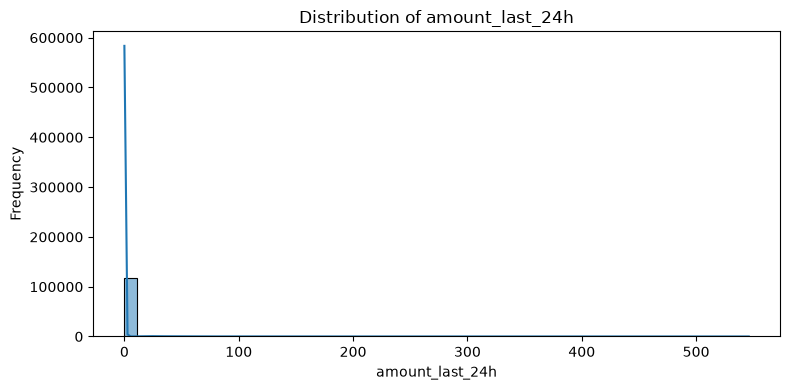

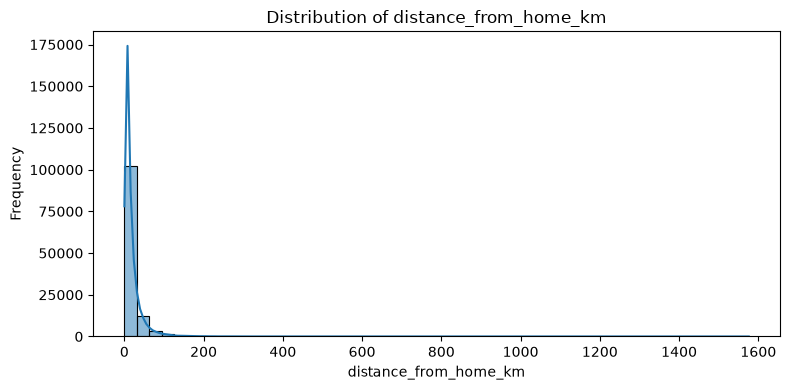

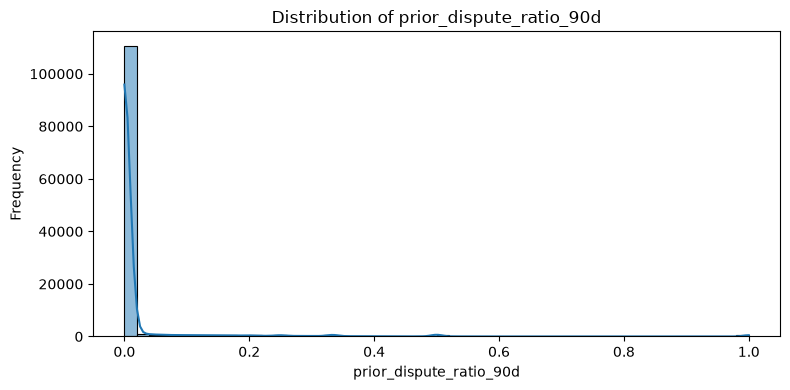

In [142]:

import matplotlib.pyplot as plt
import seaborn as sns

highly_skewed = [
    'amount_last_24h',
    'distance_from_home_km',
    'prior_dispute_ratio_90d'
]

for col in highly_skewed:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], bins=50, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

In [143]:
# investigate zero concentration
skewed_columns = [
    'amount_last_24h',
    'distance_from_home_km',
    'prior_dispute_ratio_90d'
]

zero_analysis = pd.DataFrame({
    'Zero_Count': (df[skewed_columns] == 0).sum(),
    'Zero_Percentage': (
        (df[skewed_columns] == 0).mean() * 100
    ).round(2),
    'Median': df[skewed_columns].median(),
    'Mean': df[skewed_columns].mean()
})

zero_analysis.round(2)

,Zero_Count,Zero_Percentage,Median,Mean
amount_last_24h,117384,97.82,0.00,1.04
distance_from_home_km,0,0.00,10.65,18.30
prior_dispute_ratio_90d,106731,88.94,0.00,0.02


In [144]:
# examine non-zero observations
nonzero_summary = df[
    ['amount_last_24h', 'prior_dispute_ratio_90d']
].replace(0, np.nan).describe().round(2)

nonzero_summary

,amount_last_24h,prior_dispute_ratio_90d
count,2616.00,13269.00
mean,47.67,0.18
std,39.59,0.23
min,3.07,0.00
25%,22.61,0.02
50%,36.70,0.09
75%,60.04,0.25
max,546.07,1.00


In [145]:
# check the remaining continuous features
df[
    ['distance_from_home_km',
     'distance_from_last_tx_km',
     'amount_last_1h',
     'amount_vs_avg_ratio',
     'account_age_days',
     'avg_transaction_amount_30d',
     'transaction_amount',
     'credit_limit',
     'std_transaction_amount_30d']
].describe().round(2)

,distance_from_home_km,distance_from_last_tx_km,amount_last_1h,amount_vs_avg_ratio,account_age_days,avg_transaction_amount_30d,transaction_amount,credit_limit,std_transaction_amount_30d
count,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00
mean,18.30,16.71,10.73,1.27,846.40,48.45,46.33,6723.96,13.42
std,25.45,26.33,47.67,1.49,916.13,22.88,36.97,5465.59,11.59
min,0.11,0.03,0.00,0.02,15.00,1.58,1.50,500.00,0.00
25%,5.28,4.21,0.00,0.48,311.00,41.43,22.72,3202.40,0.00
50%,10.65,8.85,0.00,0.82,537.00,50.00,36.29,5200.11,20.00
75%,21.53,18.67,0.00,1.47,1014.00,50.00,57.90,8434.15,20.00
max,1575.86,1159.35,693.62,35.00,24603.00,655.13,1030.59,73621.86,263.72


In [146]:
# investigate zero concentration
check_columns = [
    'amount_last_1h',
    'std_transaction_amount_30d',
    'avg_transaction_amount_30d'
]

pd.DataFrame({
    'Zero_Count': (df[check_columns] == 0).sum(),
    'Zero_Percentage': (
        (df[check_columns] == 0).mean() * 100
    ).round(2),
    'Unique_Values': df[check_columns].nunique()
})

,Zero_Count,Zero_Percentage,Unique_Values
amount_last_1h,108768,90.64,8061
std_transaction_amount_30d,38573,32.14,4887
avg_transaction_amount_30d,0,0.00,11619


In [147]:
# investigate repeated values
df['std_transaction_amount_30d'].value_counts().head(10)

std_transaction_amount_30d
20.00    66074
0.00     38573
1.20        18
2.80        16
9.72        16
1.70        16
1.30        15
2.54        14
0.02        14
1.21        14
Name: count, dtype: int64

In [148]:
# compare these values against fraud status
pd.crosstab(
    df['std_transaction_amount_30d'],
    df['is_fraud'],
    normalize='columns'
).loc[[0, 20]].mul(100).round(2)

is_fraud,0,1
std_transaction_amount_30d,,
0.0,32.10,32.56
20.0,55.11,54.58


In [149]:
# compare all remaining values
non_dominant = df[
    ~df['std_transaction_amount_30d'].isin([0, 20])
]

non_dominant.groupby('is_fraud')[
    'std_transaction_amount_30d'
].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,13889.0,18.67,19.14,0.01,6.10,13.30,24.57,258.02
1,1464.0,19.85,23.02,0.02,6.44,13.58,25.16,263.72


In [150]:
# summarize all continuous-feature skewness
skewness_summary = pd.DataFrame({
    'Skewness': df[continuous_columns].skew(),
    'Zero_Percentage': (
        (df[continuous_columns] == 0).mean() * 100
    )
})

skewness_summary['Skewness_Level'] = pd.cut(
    skewness_summary['Skewness'].abs(),
    bins=[-float('inf'), 0.5, 1, float('inf')],
    labels=['Approximately Symmetric', 'Moderately Skewed', 'Highly Skewed']
)

skewness_summary.sort_values(
    'Skewness', ascending=False
).round(2)

,Skewness,Zero_Percentage,Skewness_Level
amount_last_24h,14.78,97.82,Highly Skewed
distance_from_home_km,7.57,0.00,Highly Skewed
prior_dispute_ratio_90d,7.03,88.94,Highly Skewed
distance_from_last_tx_km,6.69,0.00,Highly Skewed
amount_last_1h,5.78,90.64,Highly Skewed
amount_vs_avg_ratio,4.45,0.00,Highly Skewed
account_age_days,4.19,0.00,Highly Skewed
avg_transaction_amount_30d,4.00,0.00,Highly Skewed
transaction_amount,3.11,0.00,Highly Skewed
credit_limit,2.64,0.00,Highly Skewed


In [151]:
# Calculate the correlation matrix
correlation_matrix = df[continuous_columns].corr(method='pearson')

correlation_matrix.round(2)

,transaction_amount,customer_age,account_age_days,credit_limit,credit_score,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,amount_vs_avg_ratio,avg_transaction_amount_30d,std_transaction_amount_30d,prior_dispute_ratio_90d
transaction_amount,1.00,0.00,0.07,0.00,-0.01,0.16,-0.01,-0.04,0.01,0.04,0.56,0.00,-0.00,0.06
customer_age,0.00,1.00,0.00,0.01,-0.00,-0.00,0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,0.00
account_age_days,0.07,0.00,1.00,0.00,-0.01,0.23,-0.00,-0.09,0.01,0.04,0.10,0.00,0.00,0.10
credit_limit,0.00,0.01,0.00,1.00,-0.01,-0.00,0.00,-0.00,0.00,-0.00,0.00,0.00,-0.00,0.01
credit_score,-0.01,-0.00,-0.01,-0.01,1.00,-0.02,0.00,0.01,-0.00,-0.01,-0.01,-0.00,0.00,-0.00
amount_last_1h,0.16,-0.00,0.23,-0.00,-0.02,1.00,0.02,-0.12,0.02,0.15,0.31,0.01,0.00,0.22
amount_last_24h,-0.01,0.00,-0.00,0.00,0.00,0.02,1.00,-0.13,-0.00,-0.00,-0.02,0.11,0.01,0.00
days_since_last_transaction,-0.04,-0.00,-0.09,-0.00,0.01,-0.12,-0.13,1.00,-0.00,-0.00,-0.17,0.06,0.46,-0.09
distance_from_home_km,0.01,0.00,0.01,0.00,-0.00,0.02,-0.00,-0.00,1.00,0.01,0.01,-0.00,0.00,0.01
distance_from_last_tx_km,0.04,0.00,0.04,-0.00,-0.01,0.15,-0.00,-0.00,0.01,1.00,0.10,0.00,0.00,0.06


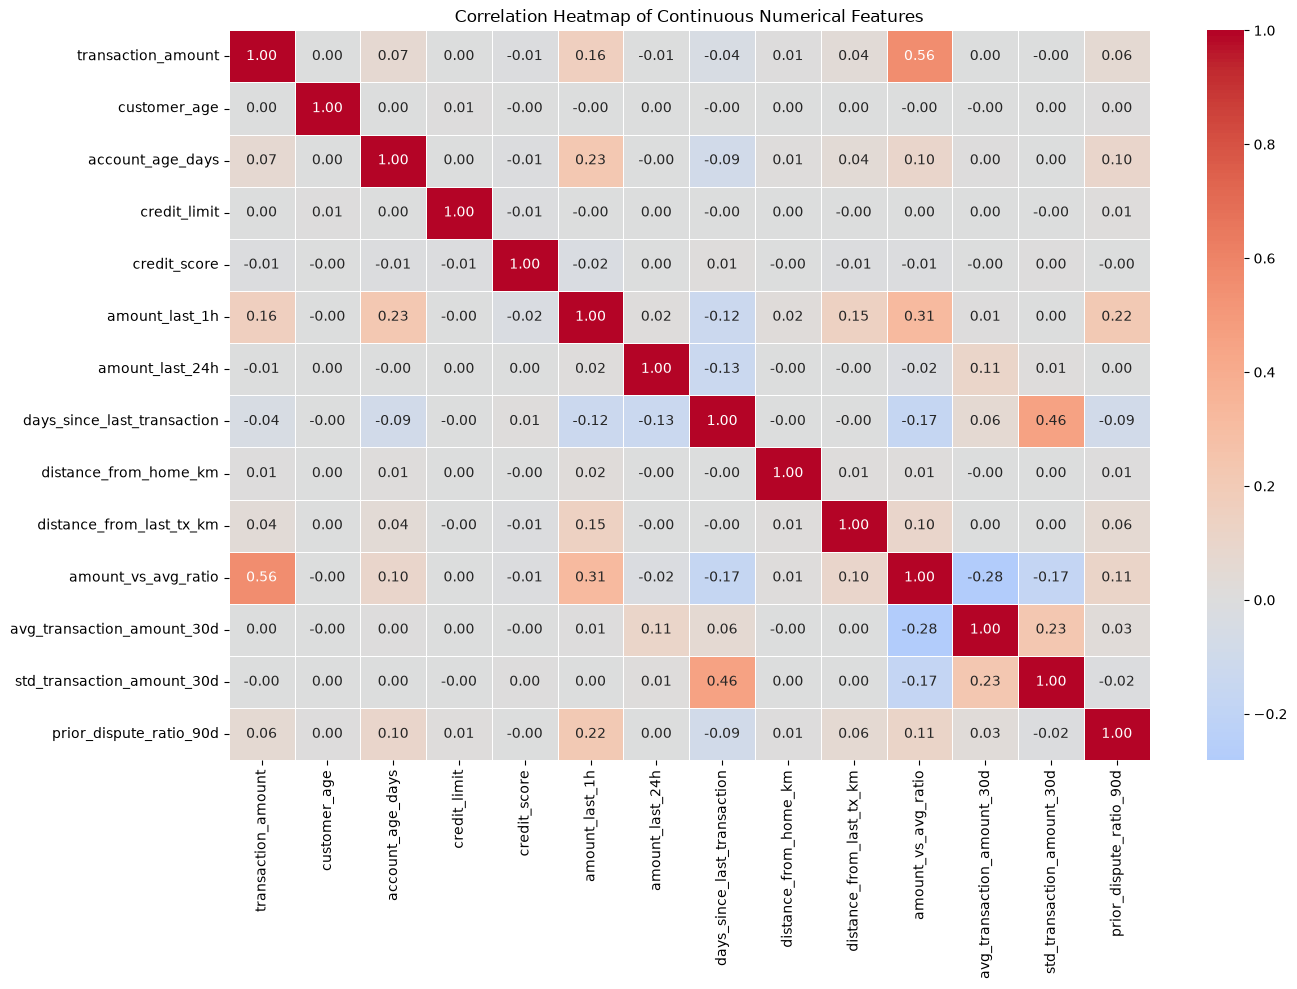

In [152]:
# visualize the correlation matrix
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap of Continuous Numerical Features')
plt.tight_layout()
plt.show()

In [153]:
# correlation with the target variable
target_correlation = (
    df[continuous_columns + ['is_fraud']]
    .corr()['is_fraud']
    .drop('is_fraud')
    .sort_values(key=abs, ascending=False)
)

target_correlation.to_frame(
    name='Correlation_with_Fraud'
).round(3)

,Correlation_with_Fraud
amount_last_1h,0.691
account_age_days,0.325
amount_vs_avg_ratio,0.303
prior_dispute_ratio_90d,0.294
days_since_last_transaction,-0.225
transaction_amount,0.204
distance_from_last_tx_km,0.126
credit_score,-0.039
distance_from_home_km,0.021
amount_last_24h,-0.003


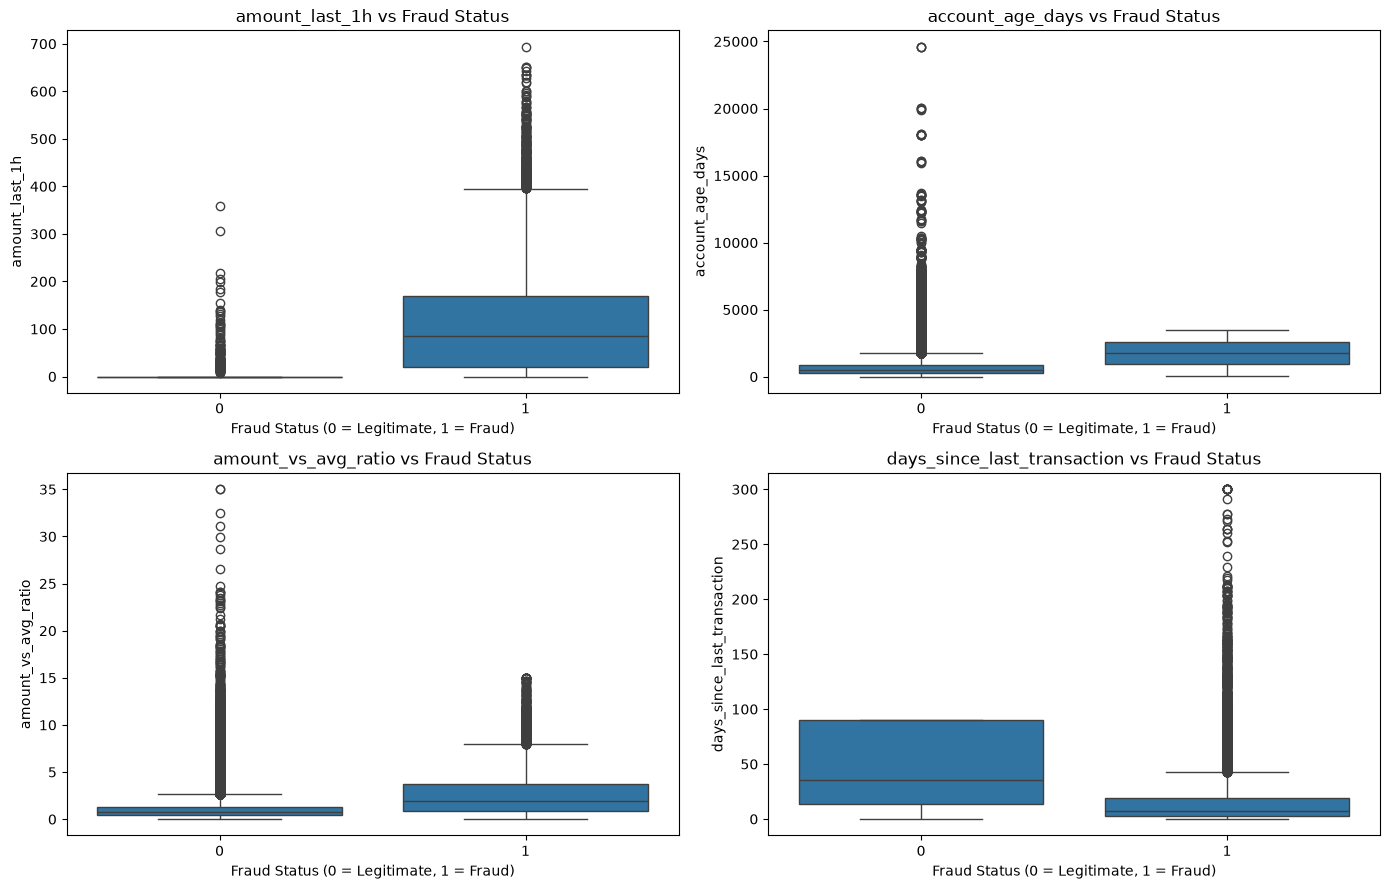

In [154]:
# visualize the strongest target relationships
important_features = [
    'amount_last_1h',
    'account_age_days',
    'amount_vs_avg_ratio',
    'days_since_last_transaction'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col, ax in zip(important_features, axes.flatten()):
    sns.boxplot(
        data=df,
        x='is_fraud',
        y=col,
        ax=ax
    )

    ax.set_title(f'{col} vs Fraud Status')
    ax.set_xlabel('Fraud Status (0 = Legitimate, 1 = Fraud)')

plt.tight_layout()
plt.show()

In [155]:
# Analyse fraud rate by transaction channel
channel_analysis = df.groupby('transaction_channel').agg(
    Transaction_Count=('is_fraud', 'count'),
    Fraud_Count=('is_fraud', 'sum'),
    Fraud_Rate=('is_fraud', 'mean')
)

channel_analysis['Fraud_Rate'] *= 100

channel_analysis.sort_values(
    'Fraud_Rate', ascending=False
).round(2)

,Transaction_Count,Fraud_Count,Fraud_Rate
transaction_channel,,,
mobile_app,19942,2688,13.48
recurring,6227,767,12.32
ecommerce,35375,4042,11.43
ATM,8230,596,7.24
POS,50226,3294,6.56


In [156]:
# analyse device_type
device_analysis = df.groupby('device_type').agg(
    Transaction_Count=('is_fraud', 'count'),
    Fraud_Count=('is_fraud', 'sum'),
    Fraud_Rate=('is_fraud', 'mean')
)

device_analysis['Fraud_Rate'] *= 100

device_analysis.sort_values(
    'Fraud_Rate', ascending=False
).round(2)

,Transaction_Count,Fraud_Count,Fraud_Rate
device_type,,,
mobile,33049,4212,12.74
tablet,6751,804,11.91
desktop,19182,2181,11.37
unknown_device,4934,452,9.16
physical_terminal,56084,3738,6.67


In [157]:
# analyse merchant_category
merchant_category_analysis = df.groupby('merchant_category').agg(
    Transaction_Count=('is_fraud', 'count'),
    Fraud_Count=('is_fraud', 'sum'),
    Fraud_Rate=('is_fraud', 'mean')
)

merchant_category_analysis['Fraud_Rate'] *= 100

merchant_category_analysis.sort_values(
    'Fraud_Rate', ascending=False
).round(2)

,Transaction_Count,Fraud_Count,Fraud_Rate
merchant_category,,,
subscription,9072,917,10.11
health,8456,830,9.82
cash_withdrawal,4867,477,9.80
digital_goods,9837,963,9.79
fuel,12811,1221,9.53
retail,21324,2027,9.51
electronics,10225,959,9.38
travel,7608,707,9.29
grocery,19368,1790,9.24


In [158]:
# analyse transaction_day_of_week
day_analysis = df.groupby('transaction_day_of_week').agg(
    Transaction_Count=('is_fraud', 'count'),
    Fraud_Count=('is_fraud', 'sum'),
    Fraud_Rate=('is_fraud', 'mean')
)

day_analysis['Fraud_Rate'] *= 100

day_analysis.sort_values(
    'Fraud_Rate', ascending=False
).round(2)

,Transaction_Count,Fraud_Count,Fraud_Rate
transaction_day_of_week,,,
Saturday,17066,1656,9.70
Tuesday,17465,1692,9.69
Wednesday,16594,1582,9.53
Sunday,17249,1630,9.45
Monday,17190,1624,9.45
Friday,17078,1590,9.31
Thursday,17358,1613,9.29


In [159]:
# analyse customer_gender
gender_analysis = df.groupby('customer_gender').agg(
    Transaction_Count=('is_fraud', 'count'),
    Fraud_Count=('is_fraud', 'sum'),
    Fraud_Rate=('is_fraud', 'mean')
)

gender_analysis['Fraud_Rate'] *= 100

gender_analysis.sort_values(
    'Fraud_Rate', ascending=False
).round(2)

,Transaction_Count,Fraud_Count,Fraud_Rate
customer_gender,,,
X,2256,226,10.02
F,58506,5585,9.55
M,55944,5271,9.42
unknown,3294,305,9.26


In [160]:
# analyse customer_country
country_analysis = df.groupby('customer_country').agg(
    Transaction_Count=('is_fraud', 'count'),
    Fraud_Count=('is_fraud', 'sum'),
    Fraud_Rate=('is_fraud', 'mean')
)

country_analysis['Fraud_Rate'] *= 100

country_analysis.sort_values(
    'Fraud_Rate', ascending=False
).round(2)

,Transaction_Count,Fraud_Count,Fraud_Rate
customer_country,,,
ES,3514,383,10.90
BR,3403,330,9.70
IE,6098,588,9.64
GB,12160,1171,9.63
US,48663,4686,9.63
NG,3549,339,9.55
SG,3643,339,9.31
IN,14688,1356,9.23
FR,5912,542,9.17


In [161]:
# analyse browser
browser_analysis = df.groupby('browser').agg(
    Transaction_Count=('is_fraud', 'count'),
    Fraud_Count=('is_fraud', 'sum'),
    Fraud_Rate=('is_fraud', 'mean')
)

browser_analysis['Fraud_Rate'] *= 100

browser_analysis.sort_values(
    'Fraud_Rate', ascending=False
).round(2)

,Transaction_Count,Fraud_Count,Fraud_Rate
browser,,,
in_app,18169,2302,12.67
Safari,11584,1392,12.02
Chrome,19751,2370,12.00
Edge,5841,689,11.80
Firefox,4154,445,10.71
none,60501,4189,6.92


In [162]:
# analyse merchant_country
merchant_country_analysis = df.groupby('merchant_country').agg(
    Transaction_Count=('is_fraud', 'count'),
    Fraud_Count=('is_fraud', 'sum'),
    Fraud_Rate=('is_fraud', 'mean')
)

merchant_country_analysis['Fraud_Rate'] *= 100

merchant_country_analysis.sort_values(
    'Fraud_Rate', ascending=False
).round(2)

,Transaction_Count,Fraud_Count,Fraud_Rate
merchant_country,,,
GB,10622,1052,9.90
FR,5393,531,9.85
CA,7531,737,9.79
SG,3111,299,9.61
NL,3177,302,9.51
US,58166,5508,9.47
NG,2723,257,9.44
ES,3802,357,9.39
IN,11569,1072,9.27


In [163]:
# analyse email_domain
email_analysis = df.groupby('email_domain').agg(
    Transaction_Count=('is_fraud', 'count'),
    Fraud_Count=('is_fraud', 'sum'),
    Fraud_Rate=('is_fraud', 'mean')
)

email_analysis['Fraud_Rate'] *= 100

email_analysis.sort_values(
    'Fraud_Rate', ascending=False
).round(2)

,Transaction_Count,Fraud_Count,Fraud_Rate
email_domain,,,
proton.me,4957,486,9.80
outlook.com,23215,2246,9.67
gmail.com,35621,3382,9.49
yahoo.com,22045,2092,9.49
icloud.com,12315,1156,9.39
other,12110,1129,9.32
business.com,9737,896,9.20


In [164]:
# categorical feature association
pd.crosstab(
    df['transaction_channel'],
    df['device_type'],
    normalize='index'
).mul(100).round(2)

device_type,desktop,mobile,physical_terminal,tablet,unknown_device
transaction_channel,,,,,
ATM,0.00,0.00,95.59,0.00,4.41
POS,0.00,0.00,96.00,0.00,4.00
ecommerce,47.21,38.27,0.00,10.41,4.12
mobile_app,0.00,86.95,0.00,9.01,4.04
recurring,39.84,34.90,0.00,20.44,4.82


In [165]:
# transaction channel vs browser
pd.crosstab(
    df['transaction_channel'],
    df['browser'],
    normalize='index'
).mul(100).round(2)

browser,Chrome,Edge,Firefox,Safari,in_app,none
transaction_channel,,,,,,
ATM,0.00,0.00,0.00,0.00,0.00,100.00
POS,0.00,0.00,0.00,0.00,0.00,100.00
ecommerce,41.64,13.95,9.96,23.90,10.55,0.00
mobile_app,12.87,0.00,0.00,7.68,69.20,10.25
recurring,39.41,14.53,10.15,25.66,10.25,0.00


In [166]:
pd.crosstab(
    df['device_type'],
    df['browser'],
    normalize='index'
).mul(100).round(2)

browser,Chrome,Edge,Firefox,Safari,in_app,none
device_type,,,,,,
desktop,41.51,13.82,10.01,24.35,10.32,0.00
mobile,26.11,6.72,4.76,15.39,41.63,5.40
physical_terminal,0.00,0.00,0.00,0.00,0.00,100.00
tablet,34.47,11.01,6.98,19.89,24.86,2.80
unknown_device,16.86,4.60,3.85,9.85,15.30,49.53


## 9. Feature Availability  and Transaction-Time Eligibility Assessment

### Objective

The objective of this stage is to determine whether each candidate feature
would be available at the time a transaction is evaluated for fraud.

Features containing information generated after the transaction,
target-derived information, or unavailable historical information
must be excluded to prevent data leakage.

In [167]:
#  Feature Availability Assessment
feature_audit = pd.DataFrame({
    'Feature': candidate_columns,
    'Availability_Status': 'Requires verification',
    'Reason': ''
})

feature_audit

,Feature,Availability_Status,Reason
0,month,Requires verification,
1,week_of_year,Requires verification,
2,transaction_amount,Requires verification,
3,merchant_category,Requires verification,
4,merchant_country,Requires verification,
5,transaction_hour,Requires verification,
6,transaction_day_of_week,Requires verification,
7,card_present,Requires verification,
8,customer_age,Requires verification,
9,customer_gender,Requires verification,


In [168]:
# classify the features we can already assess
timestamp_features = [
    'month',
    'week_of_year',
    'transaction_hour',
    'transaction_day_of_week',
    'is_weekend'
]

feature_audit.loc[
    feature_audit['Feature'].isin(timestamp_features),
    'Availability_Status'
] = 'Available at transaction time'

feature_audit.loc[
    feature_audit['Feature'].isin(timestamp_features),
    'Reason'
] = 'Derived from transaction_datetime'

feature_audit[feature_audit['Feature'].isin(timestamp_features)]

,Feature,Availability_Status,Reason
0,month,Available at transaction time,Derived from transaction_datetime
1,week_of_year,Available at transaction time,Derived from transaction_datetime
5,transaction_hour,Available at transaction time,Derived from transaction_datetime
6,transaction_day_of_week,Available at transaction time,Derived from transaction_datetime
31,is_weekend,Available at transaction time,Derived from transaction_datetime


In [169]:
# assess transaction and account attributes
transaction_account_features = [
    'transaction_amount',
    'merchant_category',
    'merchant_country',
    'card_present',
    'customer_age',
    'customer_gender',
    'customer_country',
    'account_age_days',
    'credit_limit',
    'credit_score',
    'num_cards_held',
    'international_transaction',
    'high_risk_country',
    'used_chip',
    'used_pin',
    'transaction_channel',
    'device_type',
    'browser',
    'billing_shipping_mismatch',
    'email_domain',
    'pos_entry_fallback'
]

feature_audit.loc[
    feature_audit['Feature'].isin(transaction_account_features),
    'Availability_Status'
] = 'Requires source verification'

feature_audit.loc[
    feature_audit['Feature'].isin(transaction_account_features),
    'Reason'
] = 'Plausibly available at transaction time; verify source and timing'

feature_audit[
    feature_audit['Feature'].isin(transaction_account_features)
]

,Feature,Availability_Status,Reason
2,transaction_amount,Requires source verification,Plausibly available at transaction time; verif...
3,merchant_category,Requires source verification,Plausibly available at transaction time; verif...
4,merchant_country,Requires source verification,Plausibly available at transaction time; verif...
7,card_present,Requires source verification,Plausibly available at transaction time; verif...
8,customer_age,Requires source verification,Plausibly available at transaction time; verif...
9,customer_gender,Requires source verification,Plausibly available at transaction time; verif...
10,customer_country,Requires source verification,Plausibly available at transaction time; verif...
11,account_age_days,Requires source verification,Plausibly available at transaction time; verif...
12,credit_limit,Requires source verification,Plausibly available at transaction time; verif...
13,credit_score,Requires source verification,Plausibly available at transaction time; verif...


In [170]:
# examine historical behaviour features
historical_features = [
    'transactions_last_1h',
    'transactions_last_24h',
    'transactions_last_7d',
    'amount_last_1h',
    'amount_last_24h',
    'days_since_last_transaction',
    'amount_vs_avg_ratio',
    'avg_transaction_amount_30d',
    'std_transaction_amount_30d',
    'num_declined_last_30d',
    'num_chargebacks_ever',
    'failed_auth_attempts_24h',
    'device_change_7d',
    'account_profile_change_7d',
    'merchant_velocity_24h',
    'prior_dispute_ratio_90d',
    'pin_retry_count_24h'
]

feature_audit.loc[
    feature_audit['Feature'].isin(historical_features),
    'Availability_Status'
] = 'Requires historical timing verification'

feature_audit.loc[
    feature_audit['Feature'].isin(historical_features),
    'Reason'
] = 'Verify that the feature uses only information available before the current transaction'

feature_audit[
    feature_audit['Feature'].isin(historical_features)
]

,Feature,Availability_Status,Reason
15,transactions_last_1h,Requires historical timing verification,Verify that the feature uses only information ...
16,transactions_last_24h,Requires historical timing verification,Verify that the feature uses only information ...
17,transactions_last_7d,Requires historical timing verification,Verify that the feature uses only information ...
18,amount_last_1h,Requires historical timing verification,Verify that the feature uses only information ...
19,amount_last_24h,Requires historical timing verification,Verify that the feature uses only information ...
20,days_since_last_transaction,Requires historical timing verification,Verify that the feature uses only information ...
25,amount_vs_avg_ratio,Requires historical timing verification,Verify that the feature uses only information ...
32,avg_transaction_amount_30d,Requires historical timing verification,Verify that the feature uses only information ...
33,std_transaction_amount_30d,Requires historical timing verification,Verify that the feature uses only information ...
34,num_declined_last_30d,Requires historical timing verification,Verify that the feature uses only information ...


In [171]:
distance_features = [
    'distance_from_home_km',
    'distance_from_last_tx_km'
]

feature_audit.loc[
    feature_audit['Feature'].isin(distance_features),
    'Availability_Status'
] = 'Requires source and timing verification'

feature_audit.loc[
    feature_audit['Feature'].isin(distance_features),
    'Reason'
] = 'Verify location source and whether reference information is available at transaction time'

feature_audit

,Feature,Availability_Status,Reason
0,month,Available at transaction time,Derived from transaction_datetime
1,week_of_year,Available at transaction time,Derived from transaction_datetime
2,transaction_amount,Requires source verification,Plausibly available at transaction time; verif...
3,merchant_category,Requires source verification,Plausibly available at transaction time; verif...
4,merchant_country,Requires source verification,Plausibly available at transaction time; verif...
5,transaction_hour,Available at transaction time,Derived from transaction_datetime
6,transaction_day_of_week,Available at transaction time,Derived from transaction_datetime
7,card_present,Requires source verification,Plausibly available at transaction time; verif...
8,customer_age,Requires source verification,Plausibly available at transaction time; verif...
9,customer_gender,Requires source verification,Plausibly available at transaction time; verif...


### Feature Availability Audit

A feature availability audit was conducted on all 45 candidate predictor features to assess whether they could be available at the time of transaction evaluation.

The features were classified into four groups:

- 5 features verified as available at transaction time.
- 21 features requiring source verification.
- 17 features requiring historical timing verification.
- 2 features requiring both source and timing verification.

The audit identified the need to investigate feature-generation logic, historical lookback windows, and information availability before model training.

Features were not automatically accepted as predictors based solely on their names or observed relationships with fraud. Unverified features will remain under review until their availability and leakage risks can be assessed.

### Dataset Documentation Limitation

The dataset was provided without a separate data dictionary, feature-generation documentation, or source code explaining how individual features were constructed.

Therefore, the exact calculation methods and temporal availability of several candidate predictors could not be independently verified.

Additional statistical and chronological consistency checks will be performed to identify potential leakage risks. However, these checks cannot conclusively establish the absence of temporal leakage. This limitation will be considered when selecting predictors, interpreting model performance, and presenting the project findings.

In [172]:
df['transaction_time_eligible'].value_counts(dropna=False)

transaction_time_eligible
1    118107
0      1893
Name: count, dtype: int64

In [173]:
# verify which transaction types are marked ineligible
pd.crosstab(
    df['transaction_time_eligible'],
    df['fraud_type'],
    margins=True
)

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Legitimate,Synthetic-Identity,All
transaction_time_eligible,,,,,,,
0,0,0,0,1893,0,0,1893
1,2571,2879,1898,0,108613,2146,118107
All,2571,2879,1898,1893,108613,2146,120000


### Transaction-Time Eligibility Analysis

The `transaction_time_eligible` feature was examined against `fraud_type` to understand its relationship with transaction categories.

The analysis revealed that all 1,893 Friendly-Fraud transactions have an eligibility value of 0, while all remaining 118,107 transactions have a value of 1.

This indicates a perfect association between transaction-time eligibility and the Friendly-Fraud category in the observed dataset.

Since this feature appears to distinguish transactions according to their eligibility for transaction-time prediction, it will be excluded from the initial predictor set. Its role in defining the modelling population will be investigated further before deciding whether Friendly-Fraud transactions should be included in the final modelling scope.

In [174]:
# investigate the meaning of this flag
df.loc[
    df['transaction_time_eligible'] == 0
].describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transaction_id,1893,1893,TX4042000000027,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,1893,1835,CU00004345,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
card_id,1893,1835,CA000005121,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_id,1893,1588,ME000701,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_datetime,1893,NaN,NaN,NaN,2026-03-30 13:35:54.072900,2026-01-01 00:49:00,2026-02-11 19:43:00,2026-03-30 09:00:00,2026-05-13 05:53:00,2026-06-30 21:43:00,NaN
month,1893.0,NaN,NaN,NaN,3.437401,1.0,2.0,3.0,5.0,6.0,1.716392
week_of_year,1893.0,NaN,NaN,NaN,13.581616,1.0,7.0,14.0,20.0,27.0,7.487503
drift_phase,1893.0,NaN,NaN,NaN,2.298996,1.0,1.0,2.0,3.0,4.0,1.100828
days_into_phase,1893.0,NaN,NaN,NaN,24.910724,0.0,12.0,23.0,37.0,60.0,16.369348
drift_magnitude,1893.0,NaN,NaN,NaN,0.310946,0.0,0.0,0.0,0.62,0.78,0.327191


### Investigation of Transaction-Time Eligibility

Further investigation of the 1,893 records with `transaction_time_eligible = 0` revealed the following:

- All records belong to the Friendly-Fraud category.
- All records have `is_fraud = 1`.
- All records have `transaction_time_target = EXCLUDE_POST_TRANSACTION`.
- The records occur across all four drift phases.
- Dispute-related information is available for a subset of these records, confirming that some associated information is generated after the original transaction.

These findings indicate that Friendly-Fraud is designated as ineligible for transaction-time prediction in the observed dataset.

Consequently, the initial transaction-time modelling population will provisionally consist of records with `transaction_time_eligible = 1` (118,107 transactions). The excluded Friendly-Fraud records will be retained for full-dataset EDA and separate analysis.

This modelling restriction will be explicitly documented when reporting binary and multiclass classification results.

In [175]:
pd.crosstab(
    df['transaction_time_eligible'],
    df['transaction_time_target'],
    margins=True
)

transaction_time_target,Account-Takeover,Card-Not-Present,Card-Present,EXCLUDE_POST_TRANSACTION,Legitimate,Synthetic-Identity,All
transaction_time_eligible,,,,,,,
0,0,0,0,1893,0,0,1893
1,2571,2879,1898,0,108613,2146,118107
All,2571,2879,1898,1893,108613,2146,120000


### Final Transaction-Time Eligibility Assessment

A cross-tabulation of `transaction_time_eligible` against `transaction_time_target` confirmed a perfect correspondence across all 120,000 records.

All 1,893 records with `transaction_time_eligible = 0` were assigned the target category `EXCLUDE_POST_TRANSACTION`. The remaining 118,107 records were assigned one of the five transaction-time target categories: Account-Takeover, Card-Not-Present, Card-Present, Legitimate, or Synthetic-Identity.

Therefore, the transaction-time modelling population will provisionally include only records where `transaction_time_eligible = 1`.

The 1,893 excluded records will remain available for full-dataset exploratory analysis and separate post-transaction analysis. This restriction will be maintained consistently when evaluating binary and multiclass transaction-time models.

In [176]:
# create the modelling dataset
model_df = df.loc[
    df['transaction_time_eligible'] == 1
].copy()

print("Original dataset shape:", df.shape)
print("Modelling dataset shape:", model_df.shape)

print("\nTransaction-time target distribution:")
print(model_df['transaction_time_target'].value_counts())

Original dataset shape: (120000, 73)
Modelling dataset shape: (118107, 73)

Transaction-time target distribution:
transaction_time_target
Legitimate            108613
Card-Not-Present        2879
Account-Takeover        2571
Synthetic-Identity      2146
Card-Present            1898
Name: count, dtype: int64


In [177]:
# Final target validation
pd.crosstab(
    model_df['transaction_time_target'],
    model_df['is_fraud'],
    margins=True
)

is_fraud,0,1,All
transaction_time_target,,,
Account-Takeover,0,2571,2571
Card-Not-Present,0,2879,2879
Card-Present,0,1898,1898
Legitimate,108613,0,108613
Synthetic-Identity,0,2146,2146
All,108613,9494,118107


### Target Consistency Validation

The relationship between `transaction_time_target` and `is_fraud` was validated using a cross-tabulation on the transaction-time eligible dataset.

All 108,613 Legitimate transactions were mapped to `is_fraud = 0`, while all 9,494 transactions belonging to the four eligible fraud categories were mapped to `is_fraud = 1`.

No inconsistent target mappings were identified.

The final modelling population contains 118,107 transactions, with a fraud prevalence of 8.04% and a legitimate transaction proportion of 91.96%.

The dataset is therefore suitable for proceeding with binary and multiclass classification preparation, subject to the remaining feature availability and leakage checks.